[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_AdversarialDefence_Jin2025.ipynb)

# Data re-uploading quantum classifiers and a convolutional quantum defence against adversarial images: Jin et al. 2025 step by step

**Paper.** A. Jin, T. Dutta, A. T. Ngo, A. Chattopadhyay, M. Mukherjee, *Realizing Quantum Adversarial Defense on a Trapped-ion Quantum Processor*, arXiv:2503.02436 (2025), https://arxiv.org/abs/2503.02436.

**What this notebook does.** The paper trains single-qubit *data re-uploading* quantum classifiers on MNIST digits, attacks them with a black-box *genetic algorithm* (GA) and defends them with a *convolutional quantum classifier* (DRA-CQC). The headline numbers come from a barium-ion trapped-ion processor that we cannot access. This notebook therefore **simulates the whole pipeline exactly** (single-qubit density-matrix / Bloch-vector simulation, written in NumPy and checked gate by gate against Qiskit statevector and Qiskit Aer density-matrix simulations) and runs the same attack against it. A *device-like noise model* (depolarising, bit-flip, phase-flip and read-out noise plus finite shots) stands in for the ion trap. The paper's trapped-ion numbers are used only as the values we compare against.

**How to run.** Colab, CPU runtime, *Runtime > Run all*. With `FAST_MODE = True` the notebook finishes in roughly 10 minutes (the GA is then far too small to be meaningful: use it to check that everything runs); with `FAST_MODE = False` it uses the larger budgets listed in the configuration cell (the paper's GA budget; about 2 hours on a shared 8-thread CPU, almost all of it spent in the 500-generation GA runs). **The outputs stored in this notebook come from the full run (`FAST_MODE = False`).**

**What you get at the end.** (1) the two quantum classifiers trained on MNIST digits, with confusion matrices; (2) the circuits that are actually executed, drawn with Qiskit and verified against the simulator; (3) the GA attack against the quantum models and against classical models fed with the same inputs; (4) noise sweeps and the certified-robustness quantities of the paper; (5) a side-by-side table of the paper's numbers and ours with a verdict per claim, a critical reading and exercises.

## The paper in one page

**Problem.** Can a quantum classifier resist adversarial images and realistic hardware noise? Gradient attacks such as FGSM are described as infeasible on the (hardware-in-the-loop) pipeline, so the authors use a black-box genetic algorithm.

**Data.** MNIST digits: binary (0 vs 1), 3-class (0,1,2) and 4-class (0,1,2,3). Test sets of 100 images (Figs. 2-3).

**Models.**
* *Simplistic quantum classifier (PCA + DRA).* A classical feature extractor (linear PCA for 0/1, kernel PCA for 0/1/2) reduces the image to two features; a **single qubit** re-uploads the features through alternating `Ry`/`Rz` rotations whose angles are `theta_l . [x, 1]` (eq. 5-6). 9 trainable parameters. The class is the label state with the largest population.
* *DRA-CQC (the proposed defence).* No classical feature extraction. A grid of qubits is initialised in `|0>`; every qubit re-uploads a 3x3 receptive field of the image (28x28 -> 7x7 -> 3x3 qubits), weights are shared inside a feature map like a CNN filter, each qubit is projected on `<1|`, and the final readout is a softmax / argmax (eq. 8, Fig. 5). 90 / 108 / 135 trainable parameters for 2 / 3 / 4 classes.

**Attack.** Genetic algorithm (Sec. 4.2): population 200, at most 500 generations, fitness `F = w0 * p_adv - w1 * RMSE(x, x_adv)` with `w0 = 1`, `w1 in {0.9, 1.2, 1.5}`, 100 images per trial, black box (only output probabilities).

**Claims (Table 1).** PCA-DRA: test 99.61 % (binary), 93.32 % (3-class), adversarial 45.14 % / 48.00 % (random guessing). DRA-CQC: test 98.28 / 94.10 / 91.64 %, adversarial 90.00 % (binary), 82.00 % (3-class); on the ion trap 92.00 % (binary clean), 88.00 % (binary adversarial). Robustness is also quantified with a *certified accuracy* at fidelity `1 - eps` (eq. 2) and a depolarisation radius `r_DP(p)` (eq. 4).

## What follows the paper and what had to be chosen

The paper gives no code and omits many details ("available from the corresponding author upon reasonable request"). Every row below marked *choice* is also marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Hardware | 138Ba+ ion trap (numbers in Table 1 / Figs. 2-3) | **Not available.** Exact single-qubit simulation + device-like noise model (rates are a CHOICE, see noise sweep). Optional IBM cell behind `IBM_TOKEN` is *not* the paper's device. |
| MNIST subset sizes | not given | 1200 train / 300 validation / 300 test per task (FULL), class balanced; attacks on 60 (binary) or 24 (multi-class) test images instead of 100 for run time |
| PCA-DRA depth | text says `L = 7`, Table 1 says 9 parameters | `L = 3` layers (`Ry, Rz, Ry`) x (2 features + bias) = 9 parameters, as in Table 1 / Fig. 1 |
| Kernel for 3-class | "kernel PCA" | RBF kernel PCA, gamma from the median heuristic, fitted on 400 training images |
| Label states (3 classes) | not given | Bloch vectors equally spaced on the x-z great circle |
| Training of the classifiers | genetic algorithm / on-device | Adam on exact analytic gradients of the noiseless simulation (verified against finite differences); best of several restarts on the validation split |
| CQC layer sizes | `28x28 -> 7x7 -> 3x3`, 3x3 receptive field, parameters 90 / 108 / 135 | layer 1: 2 maps, `K=3` re-uploads (`Ry,Rz,Ry`), stride 4, padding 1; layer 2: one 3x3 map per class, `K=1`, stride 2 -> **90 / 108 / 126** parameters (the paper's 4-class count of 135 is not reproduced by any layout we tried) |
| Read-out between layers | "project to `<1|`" | the projection probability `P(1)` of a layer-1 qubit is the pixel of the next tensor `T2` (a classical hand-over); class score = mean `P(1)` of the 3x3 class map |
| Output probabilities used by the attack | "probabilities of predicted classes" | class scores normalised to sum to one (physical populations); a softmax with fixed `beta` is used only for the training loss |
| GA operators | population 200, 500 generations, `w0=1`, top-k, mutation prob `p`, crossover, stop after unchanged top-10 | as the paper (uniform-noise initial population, row-wise crossover, top-20 elites, mutation prob 0.02 per pixel, stop after 30 unchanged generations); the mutation re-draws a pixel from U(0,1) (*literal*) and an ablation re-draws it around the benign pixel (*guided*) |
| Pixel scale of the RMSE | not given | pixels in [0, 1] |
| Target class of the attack | `y_adv != y` | the other class (binary) or a random wrong class (multi-class) |
| Extra analyses (not in the paper) | - | equal-perturbation GA (`RMSE <= b`), random-pixel-noise curve, classical baselines attacked by the same GA |
| Robustness certificate | eq. (2) with `1 - eps`, "probability 0.9" | `eps = 0.1`, so a point is certified iff `r_F <= 0.9` |
| `r_DP(p)` (eq. 4) | text garbled in the PDF | implemented as `p/(2(1-p)) (sqrt(pA/(1-pA)) - 1)`; only its trend is compared |

## 1. Setup

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib. Qiskit is only needed to DRAW and CROSS-CHECK the circuits.
# Pinned to the versions this notebook was tested with. A session restart may be required after the first install.
import importlib, sys
IN_COLAB = "google.colab" in sys.modules
try:
    import qiskit, qiskit_aer
    need = qiskit.__version__ != "2.5.2"
except Exception:
    need = True
if IN_COLAB and need:
    !pip -q install "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub

### Configuration

Every tunable constant lives in this one cell. `FAST_MODE = True` keeps the run short (smaller training sets, a GA with population 60 and 100 generations, a dozen attacked images). `FAST_MODE = False` uses the paper's GA budget (population 200, 500 generations) on more images; the paper attacked 100 images per trial, which is out of reach on a shared CPU (a single GA run needs 100 000 forward passes).

In [2]:
SEED = 42                      # master seed (numpy, scikit-learn, GA, shots)
FAST_MODE = False               # True: ~10 min class demo.  False: the larger budgets below (~1 h on a shared CPU)
IBM_TOKEN = ""                 # optional: only used by the (untested) real-hardware cell at the end

DATA_DIR = "qc218_data"        # cache for the MNIST download

if FAST_MODE:                  # --- small budgets ---
    N_TRAIN, N_VAL, N_TEST = 600, 200, 200      # images per task (class balanced)
    EPOCHS_CQC, DRA_EPOCHS, DRA_RESTARTS = 12, 40, 3
    N_SEEDS = 2                                 # independent trainings for mean +- std
    KPCA_FIT = 300                              # images used to fit the RBF kernel PCA
    GA_POP, GA_ITERS = 60, 100                  # paper: 200 / 500
    N_ATT_BIN, N_ATT_MC = 12, 8                 # attacked test images (paper: 100)
    N_ATT_BASE, N_ATT_SWEEP = 8, 6              # classical baselines / w1 sweep and ablation
else:                          # --- full budgets ---
    N_TRAIN, N_VAL, N_TEST = 1200, 300, 300
    EPOCHS_CQC, DRA_EPOCHS, DRA_RESTARTS = 25, 60, 5
    N_SEEDS = 3
    KPCA_FIT = 400
    GA_POP, GA_ITERS = 200, 500                 # as in the paper
    N_ATT_BIN, N_ATT_MC = 60, 24
    N_ATT_BASE, N_ATT_SWEEP = 16, 10

BUDGETS = (0.1, 0.2, 0.3)     # extra (not in the paper): RMSE budgets of the equal-perturbation GA comparison
ATTACK_RF = not FAST_MODE      # the random-forest attack is slow, FULL run only

SHOTS = 100                    # shots per read-out in the device-like simulation (CHOICE)
# CHOICE: device-like Pauli noise after every rotation + read-out flip (the paper does not publish its error budget).
# The paper says bit flips, phase flips (dephasing from magnetic-field noise / timing jitter) and depolarisation all occur.
NOISE_HW = dict(p_dep=0.01, p_x=0.005, p_z=0.02, p_ro=0.03, shots=SHOTS)
W0, W1 = 1.0, 1.0              # GA fitness weights of the headline runs (paper: w0=1, w1 in {0.9,1.2,1.5}, Table 1 uses 1.0)
W1_SWEEP = (0.9, 1.2, 1.5)
EPS_CERT = 0.1                 # certify at fidelity 1-eps = 0.9 ("probability 0.9", Fig. 2c)

In [3]:
import os, io, sys, time, math, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})

DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)           # master generator (all other generators are derived from SEED)
T0 = time.time()

# Hugging Face token: MNIST is public and needs no token. The lookup below is kept for gated mirrors:
# on Colab add your own token under Settings > Secrets > HF_TOKEN; locally set the HF_TOKEN environment variable.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

import qiskit, qiskit_aer
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | qiskit 2.5.2 | qiskit-aer 0.17.2
FAST_MODE = False | SEED = 42


## 2. Data: MNIST

The paper uses MNIST handwritten digits (60 000 training and 10 000 test images of 28x28 pixels, labels 0-9). The notebook downloads the official files from the public Hugging Face mirror `ylecun/mnist` (fallback: OpenML `mnist_784`) and caches them in `DATA_DIR`. For each task (digits 0/1, 0/1/2, 0/1/2/3) we draw class-balanced training, validation and test subsets; the validation set comes from a disjoint half of the official training file and the test set from the official test file. Pixels are scaled to [0, 1].

In [4]:
import io
from PIL import Image

def load_mnist_raw():
    """MNIST as uint8 arrays (n, 28, 28) + labels. HF mirror first, OpenML fallback."""
    cache = DATA_DIR / "mnist_uint8.npz"
    if cache.exists():
        z = np.load(cache)
        return z["xtr"], z["ytr"], z["xte"], z["yte"]
    try:
        from huggingface_hub import hf_hub_download
        def one(split):
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet",
                                repo_type="dataset", local_dir=str(DATA_DIR / "hf_mnist"),
                                token=HF_TOKEN or None)
            df = pd.read_parquet(p)
            X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
            return X, df["label"].to_numpy().astype(int)
        xtr, ytr = one("train"); xte, yte = one("test")
        source = "Hugging Face ylecun/mnist"
    except Exception as e:                                   # fallback: OpenML copy of MNIST
        print("HF mirror failed (", type(e).__name__, ") -> OpenML mnist_784")
        from sklearn.datasets import fetch_openml
        Xo, yo = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False,
                              data_home=str(DATA_DIR / "openml"))
        Xo = Xo.reshape(-1, 28, 28).astype(np.uint8); yo = yo.astype(int)
        xtr, ytr, xte, yte = Xo[:60000], yo[:60000], Xo[60000:], yo[60000:]
        source = "OpenML mnist_784"
    np.savez_compressed(cache, xtr=xtr, ytr=ytr, xte=xte, yte=yte)
    print("MNIST source:", source)
    return xtr, ytr, xte, yte


def make_split(digits, n_train, n_val, n_test, seed):
    """Class-balanced subsets of the official MNIST train/test files for the given digits."""
    rng = np.random.default_rng(seed)
    def take(X, y, n):
        per = n // len(digits); idx = []
        for d in digits:
            cand = np.flatnonzero(y == d)
            idx.append(rng.choice(cand, per, replace=False))
        idx = np.concatenate(idx); rng.shuffle(idx)
        return X[idx].astype(np.float64) / 255.0, y[idx]
    # train and validation come from disjoint parts of the official training file
    half = len(XTR_RAW) // 2
    Xa, ya = take(XTR_RAW[:half], YTR_RAW[:half], n_train)
    Xv, yv = take(XTR_RAW[half:], YTR_RAW[half:], n_val)
    Xt, yt = take(XTE_RAW, YTE_RAW, n_test)
    remap = {d: i for i, d in enumerate(digits)}
    f = np.vectorize(remap.get)
    return Xa, f(ya), Xv, f(yv), Xt, f(yt)

In [5]:
XTR_RAW, YTR_RAW, XTE_RAW, YTE_RAW = load_mnist_raw()
print("official training file:", XTR_RAW.shape, XTR_RAW.dtype, "| official test file:", XTE_RAW.shape)
TASKS = {"binary (0,1)": [0, 1], "3-class (0,1,2)": [0, 1, 2], "4-class (0,1,2,3)": [0, 1, 2, 3]}

official training file: (60000, 28, 28) uint8 | official test file: (10000, 28, 28)


## Dataset Exploration and Visualisation

Everything below is computed from the real MNIST observations. First the raw dataset (shape, feature names, the original labels and their counts), then the class distribution, example images, and 2-D scatter plots in which every point is a real image coloured by its ground-truth digit: the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates min-max scaled to [0, pi] (the range of a rotation angle, which is how the single-qubit classifier consumes features).

MNIST train  : shape (60000, 28, 28) -> flattened (60000, 784)
MNIST test   : shape (10000, 28, 28)
feature names: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3'] ... ['pixel_27_26', 'pixel_27_27'] (784 pixel features, values 0-255 rescaled to [0,1])
original label values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


,0,1,2,3,4,5,6,7,8,9
train,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test,980,1135,1032,1010,982,892,958,1028,974,1009


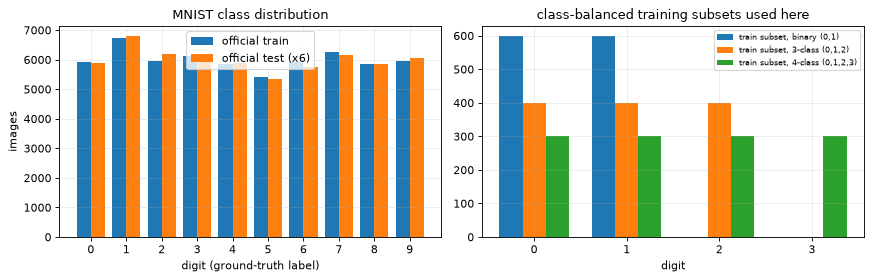

In [6]:
feature_names = [f"pixel_{r}_{c}" for r in range(28) for c in range(28)]
print("MNIST train  : shape", XTR_RAW.shape, "-> flattened", (XTR_RAW.shape[0], len(feature_names)))
print("MNIST test   : shape", XTE_RAW.shape)
print("feature names:", feature_names[:4], "...", feature_names[-2:], f"({len(feature_names)} pixel features, values 0-255 rescaled to [0,1])")
print("original label values:", sorted(np.unique(YTR_RAW)))
cnt = pd.DataFrame({"train": pd.Series(YTR_RAW).value_counts().sort_index(), "test": pd.Series(YTE_RAW).value_counts().sort_index()})
display(cnt.T)

# subsets actually used by the tasks (seed SEED)
split_counts = {}
for tname, dg in TASKS.items():
    Xa_, ya_, Xv_, yv_, Xt_, yt_ = make_split(dg, N_TRAIN, N_VAL, N_TEST, SEED)
    split_counts[tname] = {"train": np.bincount(ya_), "val": np.bincount(yv_), "test": np.bincount(yt_)}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(cnt.index - 0.2, cnt["train"], 0.4, label="official train"); ax[0].bar(cnt.index + 0.2, cnt["test"] * 6, 0.4, label="official test (x6)")
ax[0].set_xticks(range(10)); ax[0].set_xlabel("digit (ground-truth label)"); ax[0].set_ylabel("images"); ax[0].set_title("MNIST class distribution"); ax[0].legend()
w = 0.25
for j, (tname, sc_) in enumerate(split_counts.items()):
    ax[1].bar(np.arange(len(sc_["train"])) + (j - 1) * w, sc_["train"], w, label=f"train subset, {tname}")
ax[1].set_xticks(range(4)); ax[1].set_xlabel("digit"); ax[1].set_title("class-balanced training subsets used here"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

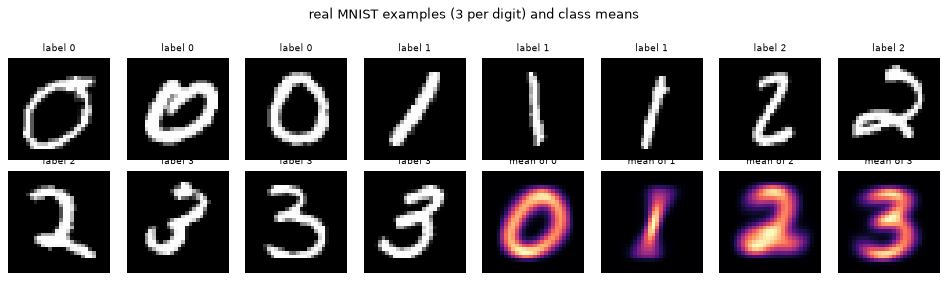

In [7]:
# example images and class mean images
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
rr = np.random.default_rng(SEED)
for d in range(4):
    idx = rr.choice(np.flatnonzero(YTR_RAW == d), 3, replace=False)
    for j, i in enumerate(idx):
        a = ax[(d * 3 + j) // 8, (d * 3 + j) % 8]; a.imshow(XTR_RAW[i], cmap="gray"); a.set_title(f"label {d}", fontsize=8); a.axis("off")
for k in range(12, 16):
    a = ax[k // 8, k % 8]; d = k - 12
    a.imshow(XTR_RAW[YTR_RAW == d].mean(0), cmap="magma"); a.set_title(f"mean of {d}", fontsize=8); a.axis("off")
plt.suptitle("real MNIST examples (3 per digit) and class means", y=1.02); plt.tight_layout(); plt.show()

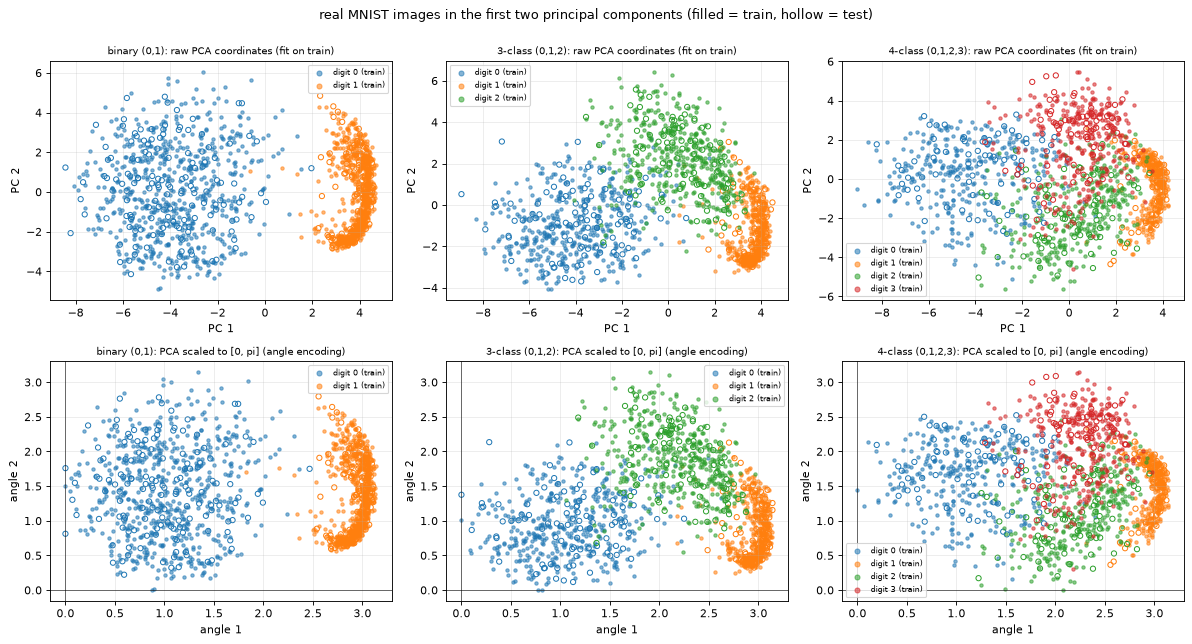

The binary task is almost linearly separable in 2-D (hence ~99 % for the PCA classifier), 0/1/2 and 0/1/2/3 overlap more,
which is why the 3-class PCA classifier uses a kernel PCA and why the paper's accuracies fall as classes are added.


In [8]:
# 2-D scatter of real images coloured by ground-truth digit. PCA and the [0,pi] scaler are fitted on the TRAINING split only.
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, (tname, dg) in enumerate(TASKS.items()):
    Xa_, ya_, Xv_, yv_, Xt_, yt_ = make_split(dg, N_TRAIN, N_VAL, N_TEST, SEED)
    pca = PCA(2, random_state=SEED).fit(Xa_.reshape(len(Xa_), -1))
    Za, Zt = pca.transform(Xa_.reshape(len(Xa_), -1)), pca.transform(Xt_.reshape(len(Xt_), -1))
    mm = MinMaxScaler((0, np.pi)).fit(Za)
    Aa, At = mm.transform(Za), np.clip(mm.transform(Zt), 0, np.pi)
    for row, (A, B, lab) in enumerate([(Za, Zt, "raw PCA coordinates (fit on train)"), (Aa, At, "PCA scaled to [0, pi] (angle encoding)")]):
        ax = axes[row, j]
        for k, d in enumerate(dg):
            ax.scatter(A[ya_ == k, 0], A[ya_ == k, 1], s=9, alpha=0.55, label=f"digit {d} (train)", color=f"C{k}")
            ax.scatter(B[yt_ == k, 0], B[yt_ == k, 1], s=22, facecolors="none", edgecolors=f"C{k}", linewidths=0.9)
        ax.set_title(f"{tname}: {lab}", fontsize=9); ax.set_xlabel("PC 1" if row == 0 else "angle 1"); ax.set_ylabel("PC 2" if row == 0 else "angle 2")
        if row == 1: ax.axhline(0, c="k", lw=.5); ax.axvline(0, c="k", lw=.5)
        ax.legend(fontsize=7, markerscale=1.5)
plt.suptitle("real MNIST images in the first two principal components (filled = train, hollow = test)", y=1.0)
plt.tight_layout(); plt.show()
print("The binary task is almost linearly separable in 2-D (hence ~99 % for the PCA classifier), 0/1/2 and 0/1/2/3 overlap more,")
print("which is why the 3-class PCA classifier uses a kernel PCA and why the paper's accuracies fall as classes are added.")

## 3. The exact simulator, the two quantum classifiers and the training loop

**Why a hand-written simulator?** Every qubit in both architectures is a *single, unentangled qubit* that starts in `|0>` and sees only single-qubit rotations (`Ry`, `Rz`), followed by a measurement. A single-qubit density matrix is a Bloch vector, `rho = (I + x X + y Y + z Z)/2`; a rotation turns the vector, and a Pauli noise channel simply shrinks its components (depolarising: all three by `1 - p`; bit flip with probability `p_x`: `y, z` by `1 - 2 p_x`; phase flip with probability `p_z`: `x, y` by `1 - 2 p_z`). This is **exact**, vectorises over thousands of qubits (the CQC has 116) and lets the GA call the model 100 000 times per image. The circuit section further below (after the training) cross-checks the simulator against Qiskit (`Statevector` and an Aer density-matrix simulation with the same noise channels) on real images.

* `DRAQubit` is the paper's single-qubit data re-uploading classifier (eq. 5-6).
* `ConvQuantumClassifier` is the DRA-CQC (eq. 8, Fig. 5).
* Training uses analytic back-propagation through the rotations (checked against finite differences below).

In [9]:
# ---------------------------------------------------------------------------------------------
# Exact single-qubit simulator in the Bloch-vector picture (equivalent to a 2x2 density matrix).
# Ry(phi): x' = x cos + z sin, z' = -x sin + z cos.   Rz(phi): x' = x cos - y sin, y' = x sin + y cos.
# A Pauli noise channel after every gate scales the Bloch vector by (nx, ny, nz):
#   depolarising p_dep: all axes (1-p_dep); bit flip p_x: y,z by (1-2 p_x); phase flip p_z: x,y by (1-2 p_z).
# ---------------------------------------------------------------------------------------------
def noise_scales(noise):
    if not noise:
        return None
    d, px, pz = noise.get("p_dep", 0.0), noise.get("p_x", 0.0), noise.get("p_z", 0.0)
    return ((1 - d) * (1 - 2 * pz), (1 - d) * (1 - 2 * pz) * (1 - 2 * px), (1 - d) * (1 - 2 * px))


def chain_forward(phis, kinds, noise=None):
    """Apply gates kinds[i](phis[i]) to |0>. Returns final Bloch vector and cache for backprop."""
    sc = noise_scales(noise)
    shp = np.broadcast(*phis).shape
    dt = phis[0].dtype if np.issubdtype(phis[0].dtype, np.floating) else np.float64
    x = np.zeros(shp, dt); y = np.zeros(shp, dt); z = np.ones(shp, dt)
    cache = []
    for kind, phi in zip(kinds, phis):
        c, s = np.cos(phi), np.sin(phi)
        if kind == "y":
            x2, y2, z2 = x * c + z * s, y, -x * s + z * c
        else:
            x2, y2, z2 = x * c - y * s, x * s + y * c, z
        cache.append((kind, c, s, (x, y, z), (x2, y2, z2)))
        x, y, z = x2, y2, z2
        if sc is not None:
            x, y, z = x * sc[0], y * sc[1], z * sc[2]
    return (x, y, z), cache, sc


def chain_backward(g, cache, sc):
    """g = (gx, gy, gz) = d loss / d final Bloch vector. Returns d loss / d phi_i for every gate."""
    gx, gy, gz = g
    dphis = [None] * len(cache)
    for i in range(len(cache) - 1, -1, -1):
        kind, c, s, vin, vout = cache[i]
        if sc is not None:                       # undo noise scaling (applied after the gate)
            gx, gy, gz = gx * sc[0], gy * sc[1], gz * sc[2]
        x2, y2, z2 = vout; x, y, z = vin
        if kind == "y":
            dphis[i] = gx * z2 + gz * (-x2)
            gx, gy, gz = c * gx - s * gz, gy, s * gx + c * gz
        else:
            dphis[i] = gx * (-y2) + gy * x2
            gx, gy, gz = c * gx + s * gy, -s * gx + c * gy, gz
    return dphis


def softmax(a, axis=-1):
    a = a - a.max(axis=axis, keepdims=True)
    e = np.exp(a)
    return e / e.sum(axis=axis, keepdims=True)

In [10]:
class Adam:
    def __init__(self, params, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
        self.p, self.lr, self.b1, self.b2, self.eps = params, lr, b1, b2, eps
        self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]; self.t = 0
    def step(self, grads):
        self.t += 1
        for i, (p, g) in enumerate(zip(self.p, grads)):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g * g
            mh = self.m[i] / (1 - self.b1 ** self.t); vh = self.v[i] / (1 - self.b2 ** self.t)
            p -= self.lr * mh / (np.sqrt(vh) + self.eps)


def label_vectors(n_classes):
    """Label states |psi_n> as Bloch vectors, equally spaced on the x-z great circle (CHOICE)."""
    if n_classes == 2:
        return np.array([[0, 0, 1.0], [0, 0, -1.0]])          # |0>, |1>
    a = 2 * np.pi * np.arange(n_classes) / n_classes
    return np.stack([np.sin(a), np.zeros(n_classes), np.cos(a)], 1)


class DRAQubit:
    """Single-qubit data re-uploading classifier (paper Sec. 4.1, eq. 5-6).
    feature vector f (d values) -> x = [f, 1]; layer l applies R(theta_l . x), alternating Ry, Rz, Ry...;
    prediction = label state with the largest population <psi_n|phi>."""
    kind = "DRA"
    def __init__(self, n_features, n_layers, n_classes, rng):
        self.d, self.L, self.N = n_features, n_layers, n_classes
        self.theta = rng.normal(0, 0.7, (n_layers, n_features + 1))
        self.kinds = ["y" if l % 2 == 0 else "z" for l in range(n_layers)]
        self.labvec = label_vectors(n_classes)
        self.beta = 6.0
    def params(self): return [self.theta]
    def n_params(self): return self.theta.size
    def _phis(self, F):
        Fa = np.concatenate([F, np.ones((len(F), 1))], 1)
        return [Fa @ self.theta[l] for l in range(self.L)], Fa
    def scores(self, F, noise=None, rng=None):
        phis, _ = self._phis(F)
        (x, y, z), _, _ = chain_forward(phis, self.kinds, noise)
        v = np.stack([x, y, z], 1)
        if noise:                                         # readout error: shrink measured vector (CHOICE)
            v = v * (1 - 2 * noise.get("p_ro", 0.0))
        s = 0.5 * (1 + v @ self.labvec.T)                 # populations of the label states
        shots = noise.get("shots") if noise else None
        if shots and rng is not None:
            s = rng.binomial(shots, np.clip(s, 0, 1)) / shots
        return s
    def proba(self, F, noise=None, rng=None):
        s = self.scores(F, noise, rng) + 1e-12
        return s / s.sum(1, keepdims=True)
    def loss_grad(self, F, y):
        phis, Fa = self._phis(F)
        (x, yy, z), cache, sc = chain_forward(phis, self.kinds, None)
        v = np.stack([x, yy, z], 1)
        s = 0.5 * (1 + v @ self.labvec.T)
        p = softmax(self.beta * s)
        loss = -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
        dl = (p - np.eye(self.N)[y]) / len(y) * self.beta        # d loss / d s
        gv = 0.5 * dl @ self.labvec                              # d loss / d v  (B,3)
        dphis = chain_backward((gv[:, 0], gv[:, 1], gv[:, 2]), cache, sc)
        g = np.stack([Fa.T @ dphis[l] for l in range(self.L)])
        return loss, [g]
    def predict(self, F, noise=None, rng=None): return self.scores(F, noise, rng).argmax(1)


class ConvQuantumClassifier:
    """DRA-CQC (paper Sec. 4.3, eq. 8, Fig. 5).  One fresh |0> qubit per receptive field.
    Layer 1: C1 feature maps of 7x7 qubits; each qubit re-uploads K1 times the 3x3 pixel patch
             (stride 4, zero padding 1) through Ry, Rz, Ry(theta . patch) and is projected on <1|.
    Layer 2: N class maps of 3x3 qubits; each qubit uploads the 3x3x C1 patch (stride 2) of the layer-1
             probabilities with K2 = 1 rotation Ry(theta . patch), projected on <1|.
    Class score = mean projection probability of the 3x3 class map; softmax(beta * score).
    Trainable parameters are shared inside a map (weight sharing as in a CNN)."""
    kind = "CQC"
    def __init__(self, n_classes, rng, C1=2, K1=3, beta=10.0):
        self.N, self.C1, self.K1, self.beta = n_classes, C1, K1, beta
        self.th1 = rng.normal(0, 0.8, (C1, K1, 9))
        self.th2 = rng.normal(0, 0.8, (n_classes, 9 * C1))
        self.kinds1 = ["y" if k % 2 == 0 else "z" for k in range(K1)]
    def params(self): return [self.th1, self.th2]
    def n_params(self): return self.th1.size + self.th2.size
    @staticmethod
    def patches1(X):                                            # (B,28,28) -> (B,7,7,9)
        P = np.pad(X, ((0, 0), (1, 1), (1, 1)))
        W = np.lib.stride_tricks.sliding_window_view(P, (3, 3), axis=(1, 2))   # (B,28,28,3,3)
        return W[:, ::4, ::4].reshape(len(X), 7, 7, 9)
    @staticmethod
    def patches2(T):                                            # (B,C1,7,7) -> (B,3,3,C1*9)
        B, C = T.shape[:2]
        out = np.empty((B, 3, 3, C, 9))
        for i in range(3):
            for j in range(3):
                out[..., 3 * i + j] = T[:, :, i:i + 5:2, j:j + 5:2][:, :, :3, :3].transpose(0, 2, 3, 1)
        return out.reshape(B, 3, 3, C * 9)
    def forward(self, X, noise=None, rng=None, keep=False):
        P1 = self.patches1(X)
        dt = X.dtype
        phi1 = np.einsum("brsi,cki->bckrs", P1, self.th1.astype(dt))       # (B,C1,K1,7,7)
        (x1, y1, z1), cache1, sc = chain_forward([phi1[:, :, k] for k in range(self.K1)], self.kinds1, noise)
        p1 = 0.5 * (1 - z1)                                     # P(measure |1>) of every layer-1 qubit
        r = noise.get("p_ro", 0.0) if noise else 0.0
        p1 = r + (1 - 2 * r) * p1
        shots = noise.get("shots") if noise else None
        if shots and rng is not None:
            p1 = rng.binomial(shots, np.clip(p1, 0, 1)) / shots
        P2 = self.patches2(p1)                                  # (B,3,3,C1*9)
        phi2 = np.einsum("bijk,nk->bnij", P2, self.th2.astype(dt))         # (B,N,3,3)
        (x2, y2, z2), cache2, sc2 = chain_forward([phi2], ["y"], noise)
        q = 0.5 * (1 - z2)
        q = r + (1 - 2 * r) * q
        if shots and rng is not None:
            q = rng.binomial(shots, np.clip(q, 0, 1)) / shots
        s = q.mean((2, 3))                                      # (B,N)
        if keep:
            return s, (P1, cache1, sc, P2, phi2, q, p1)
        return s
    def scores(self, X, noise=None, rng=None): return self.forward(X, noise, rng)
    def proba(self, X, noise=None, rng=None):
        s = self.forward(X, noise, rng) + 1e-12            # physical read-out: normalised class populations
        return s / s.sum(1, keepdims=True)
    def predict(self, X, noise=None, rng=None): return self.forward(X, noise, rng).argmax(1)
    def loss_grad(self, X, y):
        s, (P1, cache1, sc, P2, phi2, q, p1) = self.forward(X, None, None, keep=True)
        p = softmax(self.beta * s)
        loss = -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
        ds = (p - np.eye(self.N)[y]) / len(y) * self.beta        # (B,N)
        dq = np.broadcast_to(ds[:, :, None, None] / 9.0, q.shape)
        dphi2 = dq * 0.5 * np.sin(phi2)                          # q = (1 - cos phi2)/2
        g2 = np.einsum("bnij,bijk->nk", dphi2, P2)
        dP2 = np.einsum("bnij,nk->bijk", dphi2, self.th2).reshape(len(X), 3, 3, self.C1, 9)
        # scatter-add the layer-2 patch gradients back to the 7x7 maps
        dp1 = np.zeros_like(p1)
        for a in range(3):
            for b in range(3):                                   # patch position (a,b)
                for u in range(3):
                    for w in range(3):                           # offset inside patch
                        dp1[:, :, 2 * a + u, 2 * b + w] += dP2[:, a, b, :, 3 * u + w]
        dz1 = -0.5 * dp1
        zero = np.zeros_like(dz1)
        dphis = chain_backward((zero, zero, dz1), cache1, sc)
        g1 = np.stack([np.einsum("brsi,bcrs->ci", P1, dphis[k]) for k in range(self.K1)], 1)  # (C1,K1,9)
        return loss, [g1, g2]


def train_model(model, X, y, Xv, yv, epochs, batch, lr, rng, verbose=True, tag=""):
    opt = Adam(model.params(), lr=lr)
    hist = []
    for ep in range(epochs):
        idx = rng.permutation(len(X)); tot = 0.0
        for b in range(0, len(X), batch):
            bi = idx[b:b + batch]
            loss, grads = model.loss_grad(X[bi], y[bi])
            opt.step(grads); tot += loss * len(bi)
        hist.append((tot / len(X), (model.predict(Xv) == yv).mean()))
        if verbose and (ep % max(1, epochs // 5) == 0 or ep == epochs - 1):
            print(f"{tag} epoch {ep + 1:3d}/{epochs}  loss {hist[-1][0]:.4f}  val acc {hist[-1][1]:.3f}")
    return hist

In [11]:
# gradient check: analytic gradient vs central finite differences (both models, tiny batches)
_r = np.random.default_rng(0)
for _name, _m, _X, _y in [("DRAQubit (3 classes)", DRAQubit(2, 3, 3, _r), _r.normal(size=(5, 2)), _r.integers(0, 3, 5)),
                          ("ConvQuantumClassifier (3 classes)", ConvQuantumClassifier(3, _r), _r.random((4, 28, 28)), _r.integers(0, 3, 4))]:
    _, _g = _m.loss_grad(_X, _y); err = 0.0
    for p, g in zip(_m.params(), _g):
        flat = p.reshape(-1)
        for i in range(min(len(flat), 10)):
            o = flat[i]; flat[i] = o + 1e-6; lp, _ = _m.loss_grad(_X, _y); flat[i] = o - 1e-6; lm, _ = _m.loss_grad(_X, _y); flat[i] = o
            err = max(err, abs((lp - lm) / 2e-6 - g.reshape(-1)[i]))
    print(f"{_name}: max |analytic - numeric| gradient error = {err:.2e}")
    assert err < 1e-6

DRAQubit (3 classes): max |analytic - numeric| gradient error = 2.80e-10
ConvQuantumClassifier (3 classes): max |analytic - numeric| gradient error = 3.48e-10


In [12]:
from sklearn.decomposition import PCA, KernelPCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances


class Features2D:
    """Classical pre-processor of the 'simplistic' PCA-DRA classifier: 784 pixels -> 2 standardised features.
    kind='pca'  : linear PCA (binary task, paper Table 1)
    kind='kpca' : RBF kernel PCA (3-class task, paper Table 1); transform written out by hand so that the
                  black-box attack (hundreds of thousands of queries) stays fast.  Fitted on training data only."""
    def __init__(self, kind, n_fit=400, seed=0):
        self.kind, self.n_fit, self.seed = kind, n_fit, seed
    def fit(self, X):
        Xf = X.reshape(len(X), -1)
        if self.kind == "pca":
            self.pca = PCA(2, random_state=self.seed).fit(Xf)
            F = self.pca.transform(Xf)
        else:
            rng = np.random.default_rng(self.seed)
            sub = Xf[rng.choice(len(Xf), min(self.n_fit, len(Xf)), replace=False)]
            d2 = euclidean_distances(sub, squared=True)
            self.gamma = 1.0 / np.median(d2[d2 > 0])                     # CHOICE: median heuristic
            self.kp = KernelPCA(2, kernel="rbf", gamma=self.gamma, random_state=self.seed).fit(sub)
            self.sub = sub.astype(np.float32); self.sub_n = (self.sub ** 2).sum(1)
            cen = self.kp._centerer
            self.k_rows, self.k_all = cen.K_fit_rows_.astype(np.float32), float(cen.K_fit_all_)
            self.alpha = (self.kp.eigenvectors_ / np.sqrt(self.kp.eigenvalues_)).astype(np.float32)
            F = self._kpca(Xf)
            # the hand-written transform must agree with scikit-learn's KernelPCA.transform
            assert np.allclose(F[:50], self.kp.transform(Xf[:50]), atol=2e-3), "kernel-PCA transform mismatch"
        self.sc = StandardScaler().fit(F)
        return self
    def _kpca(self, Xf):
        Xf = Xf.astype(np.float32)
        d2 = (Xf ** 2).sum(1)[:, None] - 2 * Xf @ self.sub.T + self.sub_n[None, :]
        K = np.exp(-self.gamma * np.maximum(d2, 0))
        Kc = K - self.k_rows[None, :] - K.mean(1, keepdims=True) + self.k_all
        return Kc @ self.alpha
    def raw(self, X):
        Xf = X.reshape(len(X), -1)
        return self.pca.transform(Xf) if self.kind == "pca" else self._kpca(Xf)
    def __call__(self, X):
        return self.sc.transform(self.raw(X))

## 4. Training the classifiers

For every task and every seed we (i) draw the class-balanced train/validation/test subsets, (ii) fit the classical feature extractor on the training images only (PCA for the binary task, kernel PCA for the 3-class task; the 4-class task has no PCA model in the paper), (iii) train the 9-parameter PCA-DRA qubit with several restarts and keep the one with the best *validation* accuracy, and (iv) train the DRA-CQC. Training is noiseless (as in the paper's "simulation" rows); the noisy evaluations use the trained parameters unchanged.

In [13]:
def train_task(name, digits, seed):
    Xa, ya, Xv, yv, Xt, yt = make_split(digits, N_TRAIN, N_VAL, N_TEST, seed)
    N = len(digits)
    out = dict(name=name, digits=digits, N=N, seed=seed, Xa=Xa, ya=ya, Xv=Xv, yv=yv, Xt=Xt, yt=yt, feats=None, dra=None)
    r_ = np.random.default_rng(seed)
    t = time.time()
    if N <= 3:                                              # PCA-DRA exists in the paper for 2 and 3 classes
        feats = Features2D("pca" if N == 2 else "kpca", KPCA_FIT, seed).fit(Xa)
        Fa, Fv = feats(Xa), feats(Xv)
        best = None
        for r in range(DRA_RESTARTS):                       # CHOICE: restarts, best validation accuracy
            m = DRAQubit(2, 3, N, np.random.default_rng(1000 * seed + r))
            h = train_model(m, Fa, ya, Fv, yv, DRA_EPOCHS, 64, 0.1, r_, verbose=False)
            sc = (m.predict(Fv) == yv).mean()
            if best is None or sc > best[0]: best = (sc, m, h)
        out.update(feats=feats, dra=best[1], dra_hist=best[2])
    out["t_dra"] = time.time() - t; t = time.time()
    cqc = ConvQuantumClassifier(N, np.random.default_rng(1000 * seed + 7))
    out["cqc_hist"] = train_model(cqc, Xa, ya, Xv, yv, EPOCHS_CQC, 64, 0.05, r_, verbose=False)
    out["cqc"] = cqc; out["t_cqc"] = time.time() - t
    return out

RES = {}
for tname, dg in TASKS.items():
    RES[tname] = [train_task(tname, dg, SEED + s) for s in range(N_SEEDS)]
    r0 = RES[tname][0]
    print(f"{tname}: trained {N_SEEDS} seed(s); CQC parameters = {r0['cqc'].n_params()}"
          + (f", PCA-DRA parameters = {r0['dra'].n_params()}" if r0['dra'] is not None else "")
          + f"   [CQC {r0['t_cqc']:.0f} s / DRA {r0['t_dra']:.0f} s per seed]")

binary (0,1): trained 3 seed(s); CQC parameters = 90, PCA-DRA parameters = 9   [CQC 7 s / DRA 7 s per seed]


3-class (0,1,2): trained 3 seed(s); CQC parameters = 108, PCA-DRA parameters = 9   [CQC 9 s / DRA 12 s per seed]


4-class (0,1,2,3): trained 3 seed(s); CQC parameters = 126   [CQC 8 s / DRA 0 s per seed]


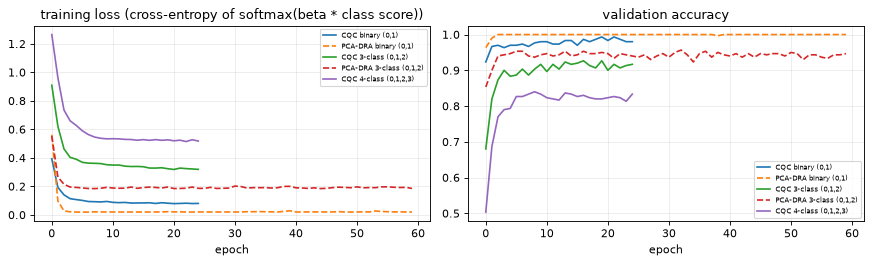

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for tname in TASKS:
    r0 = RES[tname][0]
    ax[0].plot([h[0] for h in r0["cqc_hist"]], label=f"CQC {tname}")
    ax[1].plot([h[1] for h in r0["cqc_hist"]], label=f"CQC {tname}")
    if r0["dra"] is not None:
        ax[0].plot([h[0] for h in r0["dra_hist"]], "--", label=f"PCA-DRA {tname}")
        ax[1].plot([h[1] for h in r0["dra_hist"]], "--", label=f"PCA-DRA {tname}")
ax[0].set_title("training loss (cross-entropy of softmax(beta * class score))"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=6)
ax[1].set_title("validation accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=6); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Both classifiers consist of independent single-qubit circuits. The drawings below are the **Qiskit circuits that are executed**: they are built from the *trained* parameters and a *real* test image, so every angle in the picture is a number computed from that image. Each drawing is followed by an assertion that the measured probability agrees with the NumPy simulator used everywhere else in the notebook (statevector for the ideal case; Aer density-matrix simulation with the same Pauli noise channels for the device-like case).

Assumptions where the paper omits circuit details (all documented in the table at the top): the gate order `Ry, Rz, Ry, ...` starts with `Ry` (an `Rz` first would act trivially on `|0>`); the label states of the 3-class PCA classifier are placed on the x-z great circle of the Bloch sphere; in the CQC the read-out probability of a layer-1 qubit is handed over *classically* as a pixel of the next tensor (the projections `<1|` are measurements); a CQC "qubit grid" is therefore a set of independent circuits, run in parallel or sequentially on one physical qubit.

In [15]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, pauli_error

def gate_circuit(kinds, phis, measure=True, meas_rot=None, name=None):
    qc = QuantumCircuit(1, 1 if measure else 0, name=name)
    for k, p in zip(kinds, phis):
        (qc.ry if k == "y" else qc.rz)(float(p), 0)
    if meas_rot is not None: qc.ry(-float(meas_rot), 0)      # <psi|phi> = <0| Ry(-alpha) |phi>
    if measure: qc.measure(0, 0)
    return qc

def aer_noise_model(noise):
    e = depolarizing_error(noise["p_dep"], 1)
    e = e.compose(pauli_error([("X", noise["p_x"]), ("I", 1 - noise["p_x"])]))
    e = e.compose(pauli_error([("Z", noise["p_z"]), ("I", 1 - noise["p_z"])]))
    nm = NoiseModel(basis_gates=["ry", "rz"]); nm.add_all_qubit_quantum_error(e, ["ry", "rz"])
    return nm

def aer_density_matrix(kinds, phis, noise):
    qc = gate_circuit(kinds, phis, measure=False); qc.save_density_matrix()
    sim = AerSimulator(method="density_matrix", noise_model=aer_noise_model(noise))
    return np.array(sim.run(qc, shots=1).result().data()["density_matrix"])

NOISE_GATES = {k: NOISE_HW[k] for k in ("p_dep", "p_x", "p_z")}      # gate noise only (read-out is applied analytically)
def bloch_to_rho(v): return 0.5 * (np.eye(2) + v[0] * np.array([[0, 1], [1, 0]]) + v[1] * np.array([[0, -1j], [1j, 0]]) + v[2] * np.diag([1, -1]))

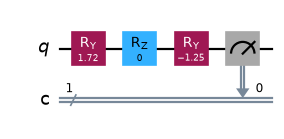

PCA-DRA (binary): qubits = 1, depth = 4 (incl. measurement), gates = {'ry': 2, 'rz': 1, 'measure': 1}, trainable parameters = 9
input: test image of digit 0 -> features [-0.64  -0.261] -> angles phi_l = theta_l . [f, 1] = [ 1.717 -0.    -1.245]
OK: NumPy Bloch simulator == Qiskit Statevector (ideal) and == Aer density matrix with depolarising+bit-flip+phase-flip noise: [0.893056 0.106944]


In [16]:
# ---- A. PCA + data re-uploading qubit (binary task): circuit executed for one real test image --------------------
rb = RES["binary (0,1)"][0]
x_img = rb["Xt"][0]; f = rb["feats"](x_img[None])                                  # 2 classical features
th = rb["dra"].theta                                                                # (3 layers, 2 features + bias)
phis_dra = [float(np.r_[f[0], 1.0] @ th[l]) for l in range(rb["dra"].L)]
qc_dra = gate_circuit(rb["dra"].kinds, phis_dra, name="PCA-DRA")
fig_ = qc_dra.draw("mpl", style="iqp"); display(fig_); plt.close(fig_)
print(f"PCA-DRA (binary): qubits = {qc_dra.num_qubits}, depth = {qc_dra.depth()} (incl. measurement), gates = {dict(qc_dra.count_ops())}, trainable parameters = {rb['dra'].n_params()}")
print("input: test image of digit", rb["digits"][rb["yt"][0]], "-> features", np.round(f[0], 3), "-> angles phi_l = theta_l . [f, 1] =", np.round(phis_dra, 3))

p_sv = Statevector(gate_circuit(rb["dra"].kinds, phis_dra, measure=False)).probabilities()          # [P(0), P(1)]
p_np = rb["dra"].scores(f)[0]                                                                       # populations of |0>, |1>
assert np.allclose(p_sv, p_np), (p_sv, p_np)
dm = aer_density_matrix(rb["dra"].kinds, phis_dra, NOISE_GATES)
noise_np = dict(NOISE_GATES, p_ro=0.0, shots=None)
p_np_noisy = rb["dra"].scores(f, noise_np)[0]
assert np.allclose(dm.diagonal().real, p_np_noisy, atol=1e-9), (dm.diagonal().real, p_np_noisy)
print("OK: NumPy Bloch simulator == Qiskit Statevector (ideal) and == Aer density matrix with depolarising+bit-flip+phase-flip noise:", np.round(p_np_noisy, 6))

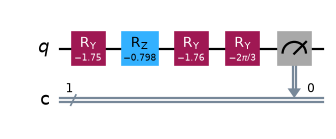

PCA-DRA (3 classes, kernel PCA features): 1 qubit, depth 5 per label state (3 gates + label rotation + measurement), trainable parameters = 9
label-state populations from Qiskit (3 circuits) == NumPy scores: [0.1802 0.7936 0.5262]


In [17]:
# ---- B. 3-class PCA classifier: same circuit, projection on three label states (Bloch vectors in the x-z plane) -----
r3 = RES["3-class (0,1,2)"][0]
f3 = r3["feats"](r3["Xt"][:1]); th3 = r3["dra"].theta
phis3 = [float(np.r_[f3[0], 1.0] @ th3[l]) for l in range(3)]
alphas = np.arctan2(r3["dra"].labvec[:, 0], r3["dra"].labvec[:, 2])                 # polar angle of every label state
qc3 = gate_circuit(r3["dra"].kinds, phis3, meas_rot=alphas[1], name="PCA-DRA 3-class, label state 1")
fig_ = qc3.draw("mpl", style="iqp"); display(fig_); plt.close(fig_)
pops = [Statevector(gate_circuit(r3["dra"].kinds, phis3, measure=False, meas_rot=a, ).copy()).probabilities()[0] for a in alphas]
assert np.allclose(pops, r3["dra"].scores(f3)[0]), (pops, r3["dra"].scores(f3)[0])
print(f"PCA-DRA (3 classes, kernel PCA features): 1 qubit, depth {qc3.depth()} per label state (3 gates + label rotation + measurement), trainable parameters = {r3['dra'].n_params()}")
print("label-state populations from Qiskit (3 circuits) == NumPy scores:", np.round(pops, 4))

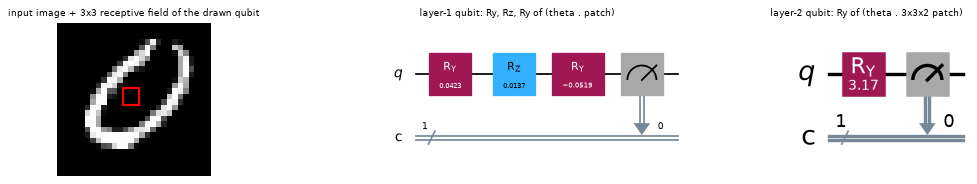

OK: all 98 layer-1 and 18 layer-2 qubits of the CQC, run as Qiskit circuits, match the NumPy simulator (max error 3.3e-16).
CQC (binary): qubits = 98 + 18 = 116 (or 1 physical qubit reused sequentially), circuit depth = 3 gates in layer 1 + 1 in layer 2 (+ measurement each), trainable parameters = 90 (54 in layer 1 shared by 49 qubits per map, 36 in layer 2)
OK: noisy layer-1 qubit == Aer density-matrix simulation: 0.029343


In [18]:
# ---- C. Convolutional quantum classifier (DRA-CQC), binary task: one real test image ----------------------------
cq = rb["cqc"]; xb = rb["Xt"][0:1]
s_np, (P1, cache1, sc1, P2, phi2, q, p1_np) = cq.forward(xb, keep=True)
phi1 = np.einsum("brsi,cki->bckrs", P1, cq.th1)                                       # angles of all 98 layer-1 qubits
# draw the qubit at map 0, position (3,3) (centre of the image) and a layer-2 qubit
circ1 = gate_circuit(cq.kinds1, phi1[0, 0, :, 3, 3], name="CQC layer 1 qubit (map 0, position 3,3)")
circ2 = gate_circuit(["y"], phi2[0, 0, 1, 1][None], name="CQC layer 2 qubit (class 0, position 1,1)")
fig, ax = plt.subplots(1, 3, figsize=(15, 2.4), gridspec_kw={"width_ratios": [1.4, 1, 1.2]})
ax[0].imshow(xb[0], cmap="gray"); ax[0].add_patch(plt.Rectangle((11.5, 11.5), 3, 3, fill=False, ec="r", lw=2)); ax[0].set_title("input image + 3x3 receptive field of the drawn qubit", fontsize=8); ax[0].axis("off")
circ1.draw("mpl", ax=ax[1], style="iqp"); ax[1].set_title("layer-1 qubit: Ry, Rz, Ry of (theta . patch)", fontsize=8)
circ2.draw("mpl", ax=ax[2], style="iqp"); ax[2].set_title("layer-2 qubit: Ry of (theta . 3x3x2 patch)", fontsize=8)
for a in ax[1:]: a.grid(False)
plt.tight_layout(); plt.show()

# execute EVERY qubit of the CQC for this image with Qiskit statevectors and compare with the NumPy forward pass
err1 = 0.0
for c in range(cq.C1):
    for r in range(7):
        for s in range(7):
            pq = Statevector(gate_circuit(cq.kinds1, phi1[0, c, :, r, s], measure=False)).probabilities()[1]
            err1 = max(err1, abs(pq - p1_np[0, c, r, s]))
err2 = 0.0
for n in range(cq.N):
    for i in range(3):
        for j in range(3):
            pq = Statevector(gate_circuit(["y"], [phi2[0, n, i, j]], measure=False)).probabilities()[1]
            err2 = max(err2, abs(pq - q[0, n, i, j]))
assert err1 < 1e-12 and err2 < 1e-12, (err1, err2)
n_q1, n_q2 = cq.C1 * 49, cq.N * 9
print(f"OK: all {n_q1} layer-1 and {n_q2} layer-2 qubits of the CQC, run as Qiskit circuits, match the NumPy simulator (max error {max(err1, err2):.1e}).")
print(f"CQC (binary): qubits = {n_q1} + {n_q2} = {n_q1 + n_q2} (or 1 physical qubit reused sequentially), circuit depth = {circ1.depth() - 1} gates in layer 1 + {circ2.depth() - 1} in layer 2 (+ measurement each), trainable parameters = {cq.n_params()} "
      f"({cq.th1.size} in layer 1 shared by 49 qubits per map, {cq.th2.size} in layer 2)")
# device-like noisy check of one layer-1 qubit against Aer
dm1 = aer_density_matrix(cq.kinds1, phi1[0, 0, :, 3, 3], NOISE_GATES)
(_, _, z_), _, _ = chain_forward([phi1[0, 0, k, 3, 3] for k in range(3)], cq.kinds1, noise_np)
assert np.isclose(dm1[1, 1].real, 0.5 * (1 - z_)), (dm1[1, 1].real, 0.5 * (1 - z_))
print("OK: noisy layer-1 qubit == Aer density-matrix simulation:", round(float(dm1[1, 1].real), 6))

In [19]:
# ---- D. parameter / qubit table for every architecture used in the notebook ------------------------------------
rows = []
for tname in TASKS:
    r0 = RES[tname][0]
    if r0["dra"] is not None:
        rows.append(dict(task=tname, model="PCA-DRA (1 qubit)", qubits=1, circuit_depth=r0["dra"].L, params=r0["dra"].n_params(), paper_params=9))
    c0 = r0["cqc"]; paper = {2: 90, 3: 108, 4: 135}[r0["N"]]
    rows.append(dict(task=tname, model="DRA-CQC", qubits=c0.C1 * 49 + c0.N * 9, circuit_depth=f"{c0.K1} + 1 (two layers)", params=c0.n_params(), paper_params=paper))
display(pd.DataFrame(rows))

,task,model,qubits,circuit_depth,params,paper_params
0,"binary (0,1)",PCA-DRA (1 qubit),1,3,9,9
1,"binary (0,1)",DRA-CQC,116,3 + 1 (two layers),90,90
2,"3-class (0,1,2)",PCA-DRA (1 qubit),1,3,9,9
3,"3-class (0,1,2)",DRA-CQC,125,3 + 1 (two layers),108,108
4,"4-class (0,1,2,3)",DRA-CQC,134,3 + 1 (two layers),126,135


## 5. Metrics: ideal simulation and device-like noisy simulation

Two evaluations of the *same trained parameters*: **ideal** (exact populations, the paper's "simulation" rows) and **device-like** (Pauli noise after every rotation, read-out flips and `SHOTS` shots per measured qubit; this stands in for the "quantum computer" rows of Table 1, see the first table for the caveat). Means and standard deviations are over `N_SEEDS` independent trainings (different subsets and initialisations).

In [20]:
def model_inputs(r, which):
    return (r["feats"](r["Xa"]), r["feats"](r["Xt"])) if which == "dra" else (r["Xa"], r["Xt"])

def acc_of(model, X, y, noise=None, seed=0):
    r_ = np.random.default_rng(seed)
    return (model.proba(X, noise, r_).argmax(1) == y).mean()

rows = []
for tname in TASKS:
    for which in ("dra", "cqc"):
        if RES[tname][0][which] is None: continue
        tr_, te_, hw_ = [], [], []
        for s, r in enumerate(RES[tname]):
            Xa_in, Xt_in = model_inputs(r, which)
            tr_.append(acc_of(r[which], Xa_in, r["ya"])); te_.append(acc_of(r[which], Xt_in, r["yt"]))
            hw_.append(acc_of(r[which], Xt_in, r["yt"], NOISE_HW, seed=SEED + s))
        rows.append(dict(task=tname, model={"dra": "PCA-DRA", "cqc": "DRA-CQC"}[which],
                         train_acc=100 * np.mean(tr_), train_std=100 * np.std(tr_), test_acc=100 * np.mean(te_), test_std=100 * np.std(te_),
                         test_acc_noisy=100 * np.mean(hw_), noisy_std=100 * np.std(hw_)))
METRICS = pd.DataFrame(rows)
display(METRICS.round(2))

,task,model,train_acc,train_std,test_acc,test_std,test_acc_noisy,noisy_std
0,"binary (0,1)",PCA-DRA,99.61,0.04,99.44,0.31,99.44,0.31
1,"binary (0,1)",DRA-CQC,99.14,0.21,99.44,0.16,94.22,4.09
2,"3-class (0,1,2)",PCA-DRA,95.11,0.31,95.78,0.31,95.67,0.82
3,"3-class (0,1,2)",DRA-CQC,91.47,0.57,92.00,1.25,88.22,2.94
4,"4-class (0,1,2,3)",DRA-CQC,85.42,0.27,84.22,1.75,75.56,8.00


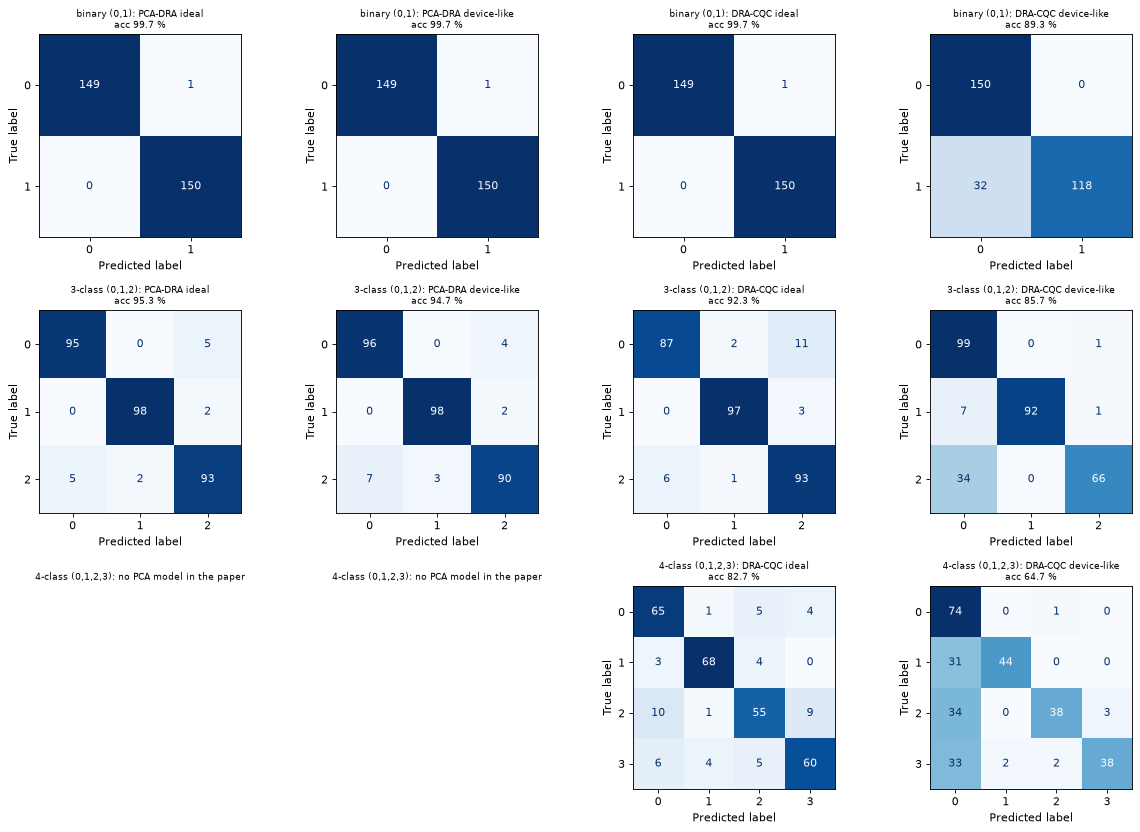

In [21]:
# confusion matrices of the first seed (rows = true digit, columns = predicted digit)
fig, axes = plt.subplots(3, 4, figsize=(15, 10.5))
for i, tname in enumerate(TASKS):
    r = RES[tname][0]
    for j, (which, noise, title) in enumerate([("dra", None, "PCA-DRA ideal"), ("dra", NOISE_HW, "PCA-DRA device-like"),
                                              ("cqc", None, "DRA-CQC ideal"), ("cqc", NOISE_HW, "DRA-CQC device-like")]):
        ax = axes[i, j]; ax.grid(False)
        if r[which] is None: ax.axis("off"); ax.set_title(f"{tname}: no PCA model in the paper", fontsize=8); continue
        Xt_in = model_inputs(r, which)[1]
        pred = r[which].proba(Xt_in, noise, np.random.default_rng(SEED)).argmax(1)
        ConfusionMatrixDisplay(confusion_matrix(r["yt"], pred), display_labels=r["digits"]).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{tname}: {title}\nacc {100 * (pred == r['yt']).mean():.1f} %", fontsize=8)
plt.tight_layout(); plt.show()

In [22]:
# timings and classical baselines trained on exactly the same inputs (first seed)
BASE = {}
rows = []
for tname in TASKS:
    r = RES[tname][0]; N = r["N"]
    Xa_pix, Xt_pix = r["Xa"].reshape(len(r["Xa"]), -1), r["Xt"].reshape(len(r["Xt"]), -1)
    cands = {"RandomForest (784 pixels)": (RandomForestClassifier(100, random_state=SEED, n_jobs=1), "pix"),
             "Logistic regression (784 pixels)": (LogisticRegression(max_iter=300), "pix"),
             "MLP 784-32-N (784 pixels)": (MLPClassifier((32,), max_iter=200, random_state=SEED), "pix")}
    if r["feats"] is not None:
        cands["SVC rbf (same 2 features as PCA-DRA)"] = (SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED), "feat")
    for nm, (clf, kind) in cands.items():
        t = time.time()
        Xa_in, Xt_in = (Xa_pix, Xt_pix) if kind == "pix" else (r["feats"](r["Xa"]), r["feats"](r["Xt"]))
        clf.fit(Xa_in, r["ya"]); acc = (clf.predict(Xt_in) == r["yt"]).mean()
        BASE[(tname, nm)] = (clf, kind); rows.append(dict(task=tname, model=nm, test_acc=100 * acc, fit_seconds=time.time() - t))
    for which, nm in (("dra", "PCA-DRA qubit"), ("cqc", "DRA-CQC")):
        if r[which] is None: continue
        m_ = METRICS[(METRICS.task == tname) & (METRICS.model == ("PCA-DRA" if which == "dra" else "DRA-CQC"))].iloc[0]
        rows.append(dict(task=tname, model=nm + " (quantum, simulated)", test_acc=m_.test_acc, fit_seconds=r["t_" + which]))
display(pd.DataFrame(rows).round(2))

,task,model,test_acc,fit_seconds
0,"binary (0,1)",RandomForest (784 pixels),100.00,1.73
1,"binary (0,1)",Logistic regression (784 pixels),99.67,0.30
2,"binary (0,1)",MLP 784-32-N (784 pixels),100.00,3.89
3,"binary (0,1)",SVC rbf (same 2 features as PCA-DRA),99.67,0.12
4,"binary (0,1)","PCA-DRA qubit (quantum, simulated)",99.44,7.05
5,"binary (0,1)","DRA-CQC (quantum, simulated)",99.44,7.00
6,"3-class (0,1,2)",RandomForest (784 pixels),99.00,4.49
7,"3-class (0,1,2)",Logistic regression (784 pixels),98.67,4.56
8,"3-class (0,1,2)",MLP 784-32-N (784 pixels),99.00,6.88
9,"3-class (0,1,2)",SVC rbf (same 2 features as PCA-DRA),96.33,0.35


## 6. The genetic-algorithm attack

Algorithm 1-2 of the paper, black box: the attacker sees only the output probability vector. A population of `GA_POP` candidate images (initialised with uniform random pixels, as in Algorithm 1) evolves for at most `GA_ITERS` generations; the top-20 candidates survive, the rest of the population is refilled by row-wise crossover of random elite pairs, and every candidate except the best is mutated pixel-wise with probability 0.02. The fitness is `F = w0 * p(y_adv) - w1 * RMSE(x, x_adv)`; the run ends early when the top-10 fitness list has not changed for 30 generations. The adversarial image is the fittest individual.

Two mutation operators are implemented, because the paper does not specify it: **literal** (`mut="uniform"`) re-draws the pixel uniformly in [0, 1]; **guided** (`mut="benign"`) re-draws it around the benign pixel, `x + N(0, 0.25^2)`. The literal one is used for all headline numbers; the guided one is an ablation (it is a much stronger attack). The *adversarial accuracy* is the fraction of attacked images that is still classified with its true label.

In [23]:
def ga_attack(proba_fn, x, y_adv, w0, w1, rng, pop=200, iters=500, topk=20, p_mut=0.02, sigma_mut=0.25,
              patience=30, init="uniform", mut="benign", rmse_budget=None):
    """Black-box genetic-algorithm attack (paper Sec. 4.2, Algorithms 1-2); only output probabilities are used.
    Population of `pop` images, fitness F = w0 * p(y_adv) - w1 * RMSE(x, x_adv) (pixels in [0,1]).
    Each generation: keep the top-k, refill by row-wise crossover of random elite pairs, mutate every
    individual except the best, stop after `iters` generations or when the top-10 fitness list has been
    unchanged for `patience` consecutive generations."""
    H, W = x.shape
    xf = x.astype(np.float32)
    if init == "uniform":                                    # Algorithm 1: pixels ~ U(0,1)
        P = rng.random((pop, H, W), dtype=np.float32)
    else:                                                    # benign image + sparse random pixels
        P = np.repeat(xf[None], pop, 0)
        m = rng.random(P.shape, dtype=np.float32) < 0.05
        P[m] = rng.random(int(m.sum()), dtype=np.float32)
    def project(Q):                                          # optional hard budget on the RMSE (equal-budget comparison)
        if rmse_budget is None: return Q
        d = Q - xf; r = np.sqrt((d ** 2).mean((1, 2), keepdims=True))
        return np.clip(xf + d * np.minimum(1.0, rmse_budget / np.maximum(r, 1e-12)), 0, 1).astype(np.float32)
    P = project(P)
    def fitness(Q):
        pr = proba_fn(Q)
        return w0 * pr[:, y_adv] - w1 * np.sqrt(((Q - xf) ** 2).mean((1, 2)))
    F = fitness(P)
    prev, same = None, 0
    for it in range(iters):
        order = np.argsort(-F)
        P, F = P[order], F[order]
        elite = P[:topk]
        nc = pop - topk
        pa = elite[rng.integers(0, topk, nc)]; pb = elite[rng.integers(0, topk, nc)]
        rows = rng.random((nc, H, 1), dtype=np.float32) < 0.5       # row-wise crossover
        child = np.where(rows, pa, pb)
        # mutation (CHOICE): a mutated pixel is re-drawn around the benign pixel value, x + N(0, sigma_mut)
        k = rng.binomial(child.size, p_mut)
        flat = rng.integers(0, child.size, k)
        if mut == "uniform":                                # literal: re-draw the pixel from U(0,1)
            child.reshape(-1)[flat] = rng.random(k, dtype=np.float32)
        else:
            child.reshape(-1)[flat] = np.clip(xf.reshape(-1)[flat % (H * W)] +
                                              rng.normal(0, sigma_mut, k).astype(np.float32), 0, 1)
        child = project(child)
        Fc = fitness(child)
        P = np.concatenate([elite, child]); F = np.concatenate([F[:topk], Fc])
        top10 = np.sort(F)[-10:]
        if prev is not None and np.array_equal(top10, prev):
            same += 1
            if same >= patience: break
        else:
            same = 0
        prev = top10
    b = int(np.argmax(F))
    return P[b].astype(np.float64), it + 1

In [24]:
# robustness helpers (certified accuracy of eq. 2, r_F, r_DP of eq. 4)
def robustness_fidelity(P):
    """Minimum robustness fidelity r_F (paper eq. 2 / Weber et al. 2021) from the two largest class probabilities."""
    Ps = np.sort(P, 1)[:, ::-1]
    pa, pb = Ps[:, 0], Ps[:, 1]
    inner = 1 - pb - pa * (1 - 2 * pb) + 2 * np.sqrt(np.clip(pa * pb * (1 - pa) * (1 - pb), 0, None))
    return 0.5 * (1 + np.sqrt(np.clip(inner, 0, None)))


def certified_accuracy(P, y, eps):
    """fraction of samples with correct label AND r_F <= 1 - eps; also the certified/uncertified split."""
    rF = robustness_fidelity(P)
    cert = rF <= 1 - eps
    correct = P.argmax(1) == y
    return (correct & cert).mean(), cert, correct, rF


def r_dp(p, pA):
    """Depolarisation robustness radius as transcribed from eq. (4) of the paper (extracted text is
    ambiguous):  r_DP(p) = p / (2 (1 - p)) * ( sqrt(pA / (1 - pA)) - 1 )."""
    pA = np.clip(pA, 0.5, 1 - 1e-9)
    return p / (2 * (1 - p)) * (np.sqrt(pA / (1 - pA)) - 1)

In [25]:
def run_attack(proba_fn, X, y, N, n_img, w1, mut, seed, noisy_proba_fn=None, tag="", budget=None):
    """GA attack against the first n_img test images; returns the adversarial images and summary statistics."""
    t0 = time.time(); adv = np.empty((n_img, 28, 28)); iters = []; targets = []
    for i in range(n_img):
        r_ = np.random.default_rng(seed * 100003 + i)
        y_adv = int((y[i] + 1 + r_.integers(0, N - 1)) % N)            # a wrong class chosen at random (binary: the other one)
        adv[i], it = ga_attack(proba_fn, X[i], y_adv, W0, w1, r_, pop=GA_POP, iters=GA_ITERS, mut=mut, rmse_budget=budget)
        iters.append(it); targets.append(y_adv)
    Pc, Pa = proba_fn(X[:n_img]), proba_fn(adv)
    rec = dict(tag=tag, n=n_img, w1=w1, mut=mut, adv=adv, targets=np.array(targets), Pc=Pc, Pa=Pa,
               clean_acc=100 * (Pc.argmax(1) == y[:n_img]).mean(), adv_acc=100 * (Pa.argmax(1) == y[:n_img]).mean(),
               targeted_success=100 * (Pa.argmax(1) == np.array(targets)).mean(),
               mean_abs_dx=100 * np.abs(adv - X[:n_img]).mean(), rmse=np.sqrt(((adv - X[:n_img]) ** 2).mean((1, 2))).mean(),
               generations=float(np.mean(iters)), seconds=time.time() - t0)
    if noisy_proba_fn is not None:                                      # transfer the images to the device-like simulation
        rec["Pc_hw"], rec["Pa_hw"] = noisy_proba_fn(X[:n_img]), noisy_proba_fn(adv)
        rec["clean_acc_hw"] = 100 * (rec["Pc_hw"].argmax(1) == y[:n_img]).mean()
        rec["adv_acc_hw"] = 100 * (rec["Pa_hw"].argmax(1) == y[:n_img]).mean()
    print(f"  {tag:46s} n={n_img:3d}  clean {rec['clean_acc']:5.1f} %  adversarial {rec['adv_acc']:5.1f} %  "
          f"mean |dx| {rec['mean_abs_dx']:5.1f} %  generations {rec['generations']:.0f}  [{rec['seconds']:.0f} s]")
    return rec

def model_fns(r, which):
    """probability functions (images -> class probabilities) for ideal and device-like evaluation"""
    if which == "dra":
        ft = r["feats"]; m = r["dra"]
        return (lambda X: m.proba(ft(X))), (lambda X, _r=np.random.default_rng(SEED + 7): m.proba(ft(X), NOISE_HW, _r))
    m = r["cqc"]
    return (lambda X: m.proba(X)), (lambda X, _r=np.random.default_rng(SEED + 8): m.proba(X, NOISE_HW, _r))

In [26]:
ATT = {}
for tname, n_att in [("binary (0,1)", N_ATT_BIN), ("3-class (0,1,2)", N_ATT_MC)]:
    r = RES[tname][0]; print(tname, "- literal GA, w0 = %.1f, w1 = %.1f" % (W0, W1))
    for which, nm in (("dra", "PCA-DRA"), ("cqc", "DRA-CQC")):
        fn, fn_hw = model_fns(r, which)
        ATT[(tname, nm, W1, "uniform")] = run_attack(fn, r["Xt"], r["yt"], r["N"], n_att, W1, "uniform", SEED, fn_hw, tag=f"{nm} / {tname}")

binary (0,1) - literal GA, w0 = 1.0, w1 = 1.0


  PCA-DRA / binary (0,1)                         n= 60  clean 100.0 %  adversarial   0.0 %  mean |dx|  29.2 %  generations 500  [547 s]


  DRA-CQC / binary (0,1)                         n= 60  clean 100.0 %  adversarial   0.0 %  mean |dx|  28.7 %  generations 500  [834 s]
3-class (0,1,2) - literal GA, w0 = 1.0, w1 = 1.0


  PCA-DRA / 3-class (0,1,2)                      n= 24  clean  95.8 %  adversarial  16.7 %  mean |dx|  23.5 %  generations 500  [622 s]


  DRA-CQC / 3-class (0,1,2)                      n= 24  clean  83.3 %  adversarial   0.0 %  mean |dx|  31.2 %  generations 500  [310 s]


In [27]:
# the same GA against classical models that receive exactly the same inputs
for tname, n_att in [("binary (0,1)", N_ATT_BASE), ("3-class (0,1,2)", N_ATT_BASE)]:
    r = RES[tname][0]; print(tname)
    for (tn, nm), (clf, kind) in BASE.items():
        if tn != tname: continue
        if nm.startswith("RandomForest") and not ATTACK_RF: continue      # slow; FULL run only
        if kind == "pix": fn = (lambda X, c=clf: c.predict_proba(X.reshape(len(X), -1)))
        else: fn = (lambda X, c=clf, ft=r["feats"]: c.predict_proba(ft(X)))
        ATT[(tname, nm, W1, "uniform")] = run_attack(fn, r["Xt"], r["yt"], r["N"], n_att, W1, "uniform", SEED, None, tag=f"{nm} / {tname}")

binary (0,1)


  RandomForest (784 pixels) / binary (0,1)       n= 16  clean 100.0 %  adversarial   0.0 %  mean |dx|  22.1 %  generations 500  [956 s]


  Logistic regression (784 pixels) / binary (0,1) n= 16  clean 100.0 %  adversarial   0.0 %  mean |dx|  23.0 %  generations 500  [110 s]


  MLP 784-32-N (784 pixels) / binary (0,1)       n= 16  clean 100.0 %  adversarial  37.5 %  mean |dx|  19.2 %  generations 500  [131 s]


  SVC rbf (same 2 features as PCA-DRA) / binary (0,1) n= 16  clean 100.0 %  adversarial  50.0 %  mean |dx|  19.1 %  generations 500  [168 s]
3-class (0,1,2)


  RandomForest (784 pixels) / 3-class (0,1,2)    n= 16  clean 100.0 %  adversarial   0.0 %  mean |dx|  23.4 %  generations 500  [951 s]


  Logistic regression (784 pixels) / 3-class (0,1,2) n= 16  clean 100.0 %  adversarial  31.2 %  mean |dx|  19.3 %  generations 500  [80 s]


  MLP 784-32-N (784 pixels) / 3-class (0,1,2)    n= 16  clean 100.0 %  adversarial  31.2 %  mean |dx|  17.7 %  generations 500  [140 s]


  SVC rbf (same 2 features as PCA-DRA) / 3-class (0,1,2) n= 16  clean  93.8 %  adversarial  18.8 %  mean |dx|  21.6 %  generations 500  [651 s]


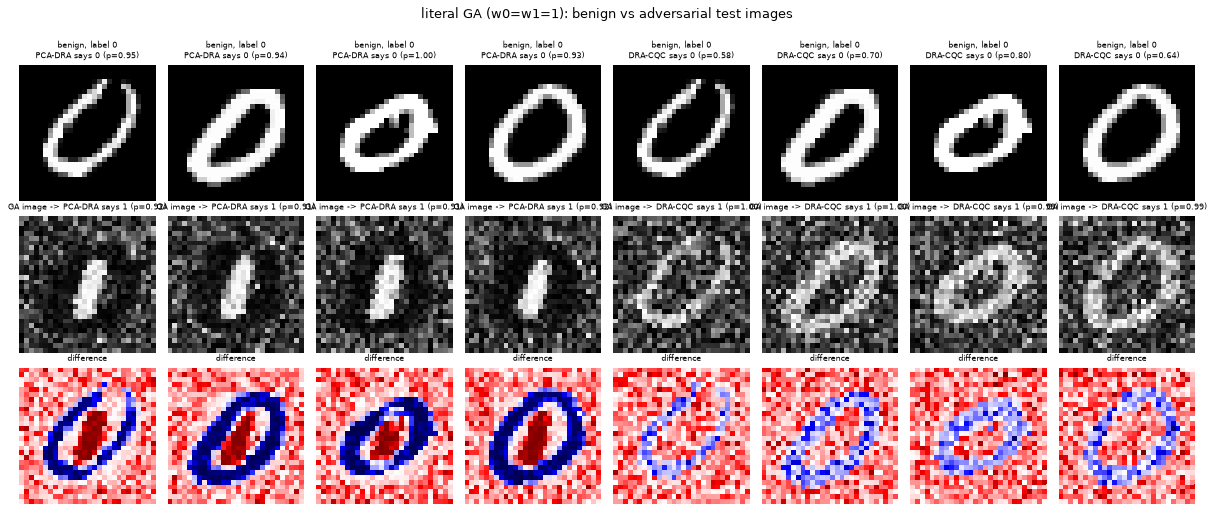

In [28]:
# examples: benign image vs GA adversarial image for each quantum model (binary task)
r = RES["binary (0,1)"][0]
fig, ax = plt.subplots(3, 8, figsize=(15, 6.4))
for col, nm in enumerate(("PCA-DRA", "DRA-CQC")):
    rec = ATT[("binary (0,1)", nm, W1, "uniform")]
    for k in range(4):
        c = col * 4 + k
        ax[0, c].imshow(r["Xt"][k], cmap="gray", vmin=0, vmax=1); ax[0, c].set_title(f"benign, label {r['digits'][r['yt'][k]]}\n{nm} says {r['digits'][rec['Pc'][k].argmax()]} (p={rec['Pc'][k].max():.2f})", fontsize=7)
        ax[1, c].imshow(rec["adv"][k], cmap="gray", vmin=0, vmax=1); ax[1, c].set_title(f"GA image -> {nm} says {r['digits'][rec['Pa'][k].argmax()]} (p={rec['Pa'][k].max():.2f})", fontsize=7)
        ax[2, c].imshow(rec["adv"][k] - r["Xt"][k], cmap="seismic", vmin=-1, vmax=1); ax[2, c].set_title("difference", fontsize=7)
for a in ax.ravel(): a.axis("off")
plt.suptitle("literal GA (w0=w1=1): benign vs adversarial test images", y=1.0); plt.tight_layout(); plt.show()

In [29]:
def attack_table(keys):
    rows = []
    for k in keys:
        rec = ATT[k]
        rows.append(dict(task=k[0], model=k[1], w1=k[2], mutation=("literal" if k[3] == "uniform" else "guided"), n_images=rec["n"],
                         clean_acc=rec["clean_acc"], adv_acc=rec["adv_acc"], adv_acc_noisy=rec.get("adv_acc_hw", np.nan),
                         mean_abs_pixel_change_pct=rec["mean_abs_dx"], rmse=rec["rmse"], generations=rec["generations"], seconds=rec["seconds"]))
    return pd.DataFrame(rows)
display(attack_table([k for k in ATT if k[2] == W1 and k[3] == "uniform"]).round(2))

,task,model,w1,mutation,n_images,clean_acc,adv_acc,adv_acc_noisy,mean_abs_pixel_change_pct,rmse,generations,seconds
0,"binary (0,1)",PCA-DRA,1.0,literal,60,100.00,0.00,0.00,29.22,0.38,500.0,547.34
1,"binary (0,1)",DRA-CQC,1.0,literal,60,100.00,0.00,0.00,28.74,0.36,500.0,834.19
2,"3-class (0,1,2)",PCA-DRA,1.0,literal,24,95.83,16.67,20.83,23.47,0.31,500.0,621.79
3,"3-class (0,1,2)",DRA-CQC,1.0,literal,24,83.33,0.00,0.00,31.20,0.39,500.0,310.17
4,"binary (0,1)",RandomForest (784 pixels),1.0,literal,16,100.00,0.00,NaN,22.13,0.29,500.0,955.99
5,"binary (0,1)",Logistic regression (784 pixels),1.0,literal,16,100.00,0.00,NaN,23.01,0.30,500.0,110.24
6,"binary (0,1)",MLP 784-32-N (784 pixels),1.0,literal,16,100.00,37.50,NaN,19.17,0.24,500.0,130.79
7,"binary (0,1)",SVC rbf (same 2 features as PCA-DRA),1.0,literal,16,100.00,50.00,NaN,19.12,0.24,500.0,168.21
8,"3-class (0,1,2)",RandomForest (784 pixels),1.0,literal,16,100.00,0.00,NaN,23.35,0.30,500.0,950.95
9,"3-class (0,1,2)",Logistic regression (784 pixels),1.0,literal,16,100.00,31.25,NaN,19.33,0.24,500.0,80.16


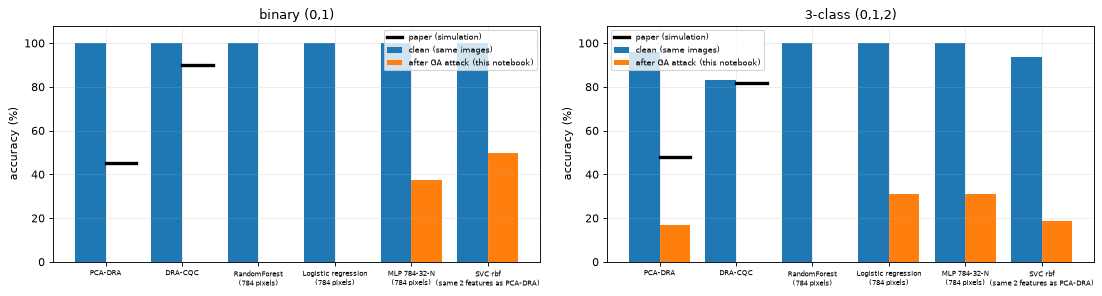

In [30]:
# adversarial accuracy per model: bars with the paper's values for the quantum models
paper_adv = {("binary (0,1)", "PCA-DRA"): 45.14, ("binary (0,1)", "DRA-CQC"): 90.00, ("3-class (0,1,2)", "PCA-DRA"): 48.00, ("3-class (0,1,2)", "DRA-CQC"): 82.00}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, tname in zip(axes, ["binary (0,1)", "3-class (0,1,2)"]):
    ks = [k for k in ATT if k[0] == tname and k[2] == W1 and k[3] == "uniform"]
    xs = np.arange(len(ks)); ax.bar(xs - 0.2, [ATT[k]["clean_acc"] for k in ks], 0.4, label="clean (same images)")
    ax.bar(xs + 0.2, [ATT[k]["adv_acc"] for k in ks], 0.4, label="after GA attack (this notebook)")
    for i, k in enumerate(ks):
        if (k[0], k[1]) in paper_adv: ax.plot([i + 0.0, i + 0.4], [paper_adv[(k[0], k[1])]] * 2, "k-", lw=3, label="paper (simulation)" if i == 0 else None)
    ax.set_xticks(xs); ax.set_xticklabels([k[1].replace(" (", "\n(") for k in ks], fontsize=6.5); ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 108); ax.set_title(tname); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [31]:
# ablation and sensitivity (binary task, quantum models): w1 sweep with the literal GA, and the guided mutation
r = RES["binary (0,1)"][0]
print("binary (0,1): w1 sweep (literal GA) and guided-mutation ablation, first %d test images" % N_ATT_SWEEP)
for which, nm in (("dra", "PCA-DRA"), ("cqc", "DRA-CQC")):
    fn, fn_hw = model_fns(r, which)
    for w1 in W1_SWEEP:
        ATT[("binary (0,1)", nm, w1, "uniform")] = run_attack(fn, r["Xt"], r["yt"], 2, N_ATT_SWEEP, w1, "uniform", SEED, fn_hw, tag=f"{nm} w1={w1} literal")
    ATT[("binary (0,1)", nm, W1, "benign")] = run_attack(fn, r["Xt"], r["yt"], 2, N_ATT_SWEEP, W1, "benign", SEED, fn_hw, tag=f"{nm} w1={W1} guided")
display(attack_table([k for k in ATT if k[0] == "binary (0,1)" and k[1] in ("PCA-DRA", "DRA-CQC") and (k[2] != W1 or k[3] == "benign")]).round(2))

binary (0,1): w1 sweep (literal GA) and guided-mutation ablation, first 10 test images


  PCA-DRA w1=0.9 literal                         n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  31.7 %  generations 500  [80 s]


  PCA-DRA w1=1.2 literal                         n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  30.9 %  generations 500  [78 s]


  PCA-DRA w1=1.5 literal                         n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  29.9 %  generations 500  [77 s]


  PCA-DRA w1=1.0 guided                          n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  16.9 %  generations 500  [92 s]


  DRA-CQC w1=0.9 literal                         n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  28.0 %  generations 500  [99 s]


  DRA-CQC w1=1.2 literal                         n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  26.4 %  generations 500  [98 s]


  DRA-CQC w1=1.5 literal                         n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  25.4 %  generations 500  [91 s]


  DRA-CQC w1=1.0 guided                          n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|   6.1 %  generations 500  [102 s]


,task,model,w1,mutation,n_images,clean_acc,adv_acc,adv_acc_noisy,mean_abs_pixel_change_pct,rmse,generations,seconds
0,"binary (0,1)",PCA-DRA,0.9,literal,10,100.0,0.0,0.0,31.71,0.41,500.0,80.28
1,"binary (0,1)",PCA-DRA,1.2,literal,10,100.0,0.0,0.0,30.91,0.40,500.0,78.11
2,"binary (0,1)",PCA-DRA,1.5,literal,10,100.0,0.0,0.0,29.87,0.39,500.0,76.78
3,"binary (0,1)",PCA-DRA,1.0,guided,10,100.0,0.0,0.0,16.94,0.31,500.0,91.70
4,"binary (0,1)",DRA-CQC,0.9,literal,10,100.0,0.0,0.0,28.01,0.35,500.0,98.78
5,"binary (0,1)",DRA-CQC,1.2,literal,10,100.0,0.0,0.0,26.37,0.33,500.0,98.18
6,"binary (0,1)",DRA-CQC,1.5,literal,10,100.0,0.0,0.0,25.37,0.32,500.0,91.40
7,"binary (0,1)",DRA-CQC,1.0,guided,10,100.0,0.0,0.0,6.13,0.15,500.0,101.71


### Equal-perturbation comparison (extra, not in the paper)

The literal GA ends at whatever perturbation its fitness trade-off dictates, and that is different for every model, so adversarial accuracies are not directly comparable. Here the same GA is run with a **hard budget** on the perturbation, `RMSE(x, x_adv) <= b` (every candidate is rescaled into the budget, `w1 = 0`, the fitness is just `p(y_adv)`), for `b` in `BUDGETS`. A mean absolute pixel change of 12.6 % (the paper's figure) corresponds to `b` of roughly 0.1-0.3. We also add a non-adaptive reference: accuracy when a fraction of the pixels is replaced by uniform random noise.

In [32]:
ATTB = {}
print("binary (0,1): GA with a hard RMSE budget (first %d test images)" % N_ATT_SWEEP)
r = RES["binary (0,1)"][0]
for which, nm in (("dra", "PCA-DRA"), ("cqc", "DRA-CQC")):
    fn, fn_hw = model_fns(r, which)
    for b in BUDGETS:
        ATTB[(nm, b)] = run_attack(fn, r["Xt"], r["yt"], 2, N_ATT_SWEEP, 0.0, "uniform", SEED, fn_hw, tag=f"{nm} RMSE <= {b}", budget=b)
for (tn, nm), (clf, kind) in BASE.items():
    if tn != "binary (0,1)" or nm.startswith("RandomForest"): continue
    fn = (lambda X, c=clf: c.predict_proba(X.reshape(len(X), -1))) if kind == "pix" else (lambda X, c=clf, ft=r["feats"]: c.predict_proba(ft(X)))
    ATTB[(nm, 0.2)] = run_attack(fn, r["Xt"], r["yt"], 2, N_ATT_SWEEP, 0.0, "uniform", SEED, None, tag=f"{nm} RMSE <= 0.2", budget=0.2)
rows = [dict(model=k[0], rmse_budget=k[1], n_images=v["n"], clean_acc=v["clean_acc"], adv_acc=v["adv_acc"], adv_acc_noisy=v.get("adv_acc_hw", np.nan),
             achieved_rmse=v["rmse"], mean_abs_pixel_change_pct=v["mean_abs_dx"]) for k, v in ATTB.items()]
display(pd.DataFrame(rows).round(2))

binary (0,1): GA with a hard RMSE budget (first 10 test images)


  PCA-DRA RMSE <= 0.1                            n= 10  clean 100.0 %  adversarial 100.0 %  mean |dx|   3.9 %  generations 500  [60 s]


  PCA-DRA RMSE <= 0.2                            n= 10  clean 100.0 %  adversarial  60.0 %  mean |dx|  11.5 %  generations 500  [76 s]


  PCA-DRA RMSE <= 0.3                            n= 10  clean 100.0 %  adversarial  30.0 %  mean |dx|  21.0 %  generations 500  [80 s]


  DRA-CQC RMSE <= 0.1                            n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|   3.8 %  generations 410  [83 s]


...

  DRA-CQC RMSE <= 0.3                            n= 10  clean 100.0 %  adversarial   0.0 %  mean |dx|  23.5 %  generations 372  [73 s]


  Logistic regression (784 pixels) RMSE <= 0.2   n= 10  clean 100.0 %  adversarial  40.0 %  mean |dx|  11.7 %  generations 500  [74 s]


  MLP 784-32-N (784 pixels) RMSE <= 0.2          n= 10  clean 100.0 %  adversarial  30.0 %  mean |dx|  11.5 %  generations 500  [64 s]


  SVC rbf (same 2 features as PCA-DRA) RMSE <= 0.2 n= 10  clean 100.0 %  adversarial  60.0 %  mean |dx|  11.5 %  generations 500  [93 s]


,model,rmse_budget,n_images,clean_acc,adv_acc,adv_acc_noisy,achieved_rmse,mean_abs_pixel_change_pct
0,PCA-DRA,0.1,10,100.0,100.0,100.0,0.1,3.88
1,PCA-DRA,0.2,10,100.0,60.0,60.0,0.2,11.50
2,PCA-DRA,0.3,10,100.0,30.0,30.0,0.3,21.00
3,DRA-CQC,0.1,10,100.0,0.0,0.0,0.1,3.79
4,DRA-CQC,0.2,10,100.0,0.0,0.0,0.2,12.94
5,DRA-CQC,0.3,10,100.0,0.0,0.0,0.3,23.55
6,Logistic regression (784 pixels),0.2,10,100.0,40.0,NaN,0.2,11.65
7,MLP 784-32-N (784 pixels),0.2,10,100.0,30.0,NaN,0.2,11.49
8,SVC rbf (same 2 features as PCA-DRA),0.2,10,100.0,60.0,NaN,0.2,11.54


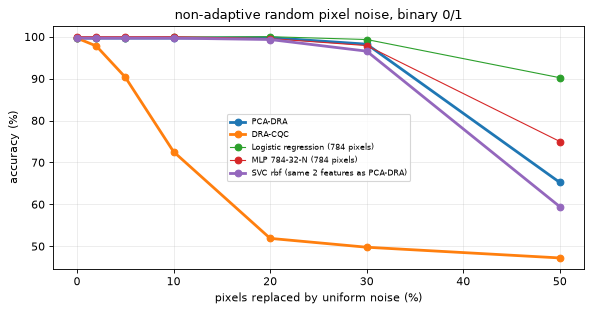

In [33]:
# non-adaptive reference: replace a fraction q of the pixels by U(0,1) noise (binary task, all test images)
r = RES["binary (0,1)"][0]; qs = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
curves = {}
fns = {"PCA-DRA": model_fns(r, "dra")[0], "DRA-CQC": model_fns(r, "cqc")[0]}
for (tn, nm), (clf, kind) in BASE.items():
    if tn == "binary (0,1)" and not nm.startswith("RandomForest"):
        fns[nm] = (lambda X, c=clf: c.predict_proba(X.reshape(len(X), -1))) if kind == "pix" else (lambda X, c=clf, ft=r["feats"]: c.predict_proba(ft(X)))
for nm, fn in fns.items():
    accs = []
    for q in qs:
        a = []
        for rep in range(3):
            g = np.random.default_rng(SEED + rep); Xn = r["Xt"].copy(); m = g.random(Xn.shape) < q
            Xn[m] = g.random(int(m.sum())); a.append((fn(Xn).argmax(1) == r["yt"]).mean())
        accs.append(100 * np.mean(a))
    curves[nm] = accs
fig, ax = plt.subplots(figsize=(7.5, 4))
for nm, accs in curves.items(): ax.plot(100 * np.array(qs), accs, "-o", label=nm, lw=2.5 if "DRA" in nm else 1)
ax.set_xlabel("pixels replaced by uniform noise (%)"); ax.set_ylabel("accuracy (%)"); ax.set_title("non-adaptive random pixel noise, binary 0/1"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

### Note on the CQC's noise sensitivity (separate helper run, not executed in this notebook)

The CQC loses accuracy quickly under random pixel noise (curve above). A separate helper run, with the same set-up and seeds but **not part of this notebook's execution** (its outputs are therefore not stored here), retrained the binary CQC with initial weight standard deviations 0.8, 0.3, 0.1 and 0.03. A smaller initialisation helped only marginally (accuracy with 10 % random pixels about 64 % -> 76 %, with 20 % about 51 % -> 54 %) and the equal-budget GA (RMSE <= 0.2, 10 images) still fooled every variant, so the sensitivity appears to be a property of this architecture trained without noise rather than of the initialisation. Exercise 6 asks you to reproduce this check.

## 7. Noise: device-like noisy simulation and a noise sweep

The paper's hardware numbers (Table 1) differ from the simulation: PCA-DRA 3-class drops from 93.3 % to 64.1 %, the CQC loses at most a few points. The error budget of the ion trap is not published, so we do not tune a noise model to reproduce the drop. Instead we scale *all* error rates of the device-like model by a factor `m` (`m = 1` is `NOISE_HW`) and show clean and adversarial accuracy as functions of `m`. The adversarial images are the ones generated above against the noiseless models, evaluated on the noisy models (an attack made in simulation, replayed on the device).

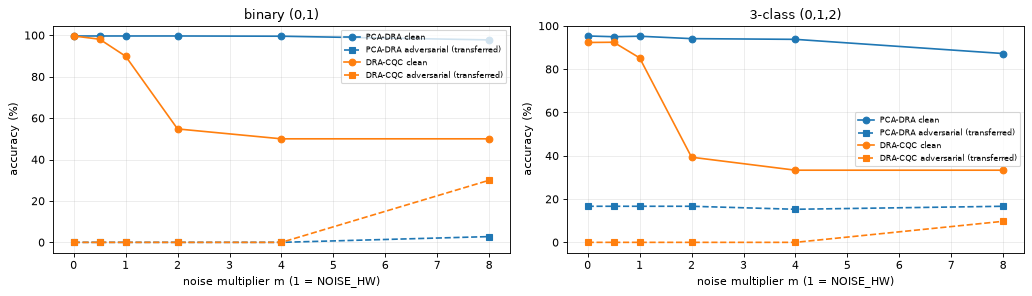

noise_multiplier          0.0   0.5   1.0   2.0   4.0   8.0
task            model                                      
3-class (0,1,2) DRA-CQC  92.3  92.4  85.2  39.3  33.3  33.3
                PCA-DRA  95.3  95.0  95.2  94.1  93.8  87.2
binary (0,1)    DRA-CQC  99.7  98.1  89.9  54.8  50.0  50.0
                PCA-DRA  99.7  99.7  99.7  99.7  99.6  97.8

In [34]:
def scaled_noise(m):
    return dict(p_dep=min(NOISE_HW["p_dep"] * m, 0.5), p_x=min(NOISE_HW["p_x"] * m, 0.5), p_z=min(NOISE_HW["p_z"] * m, 0.5), p_ro=min(NOISE_HW["p_ro"] * m, 0.5), shots=SHOTS)
MULTS = [0, 0.5, 1, 2, 4, 8]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8)); sweep_rows = []
for ax, tname in zip(axes, ["binary (0,1)", "3-class (0,1,2)"]):
    r = RES[tname][0]
    for which, nm, col in (("dra", "PCA-DRA", "C0"), ("cqc", "DRA-CQC", "C1")):
        Xin = r["feats"](r["Xt"]) if which == "dra" else r["Xt"]
        rec = ATT[(tname, nm, W1, "uniform")]
        Ain = (r["feats"](rec["adv"]) if which == "dra" else rec["adv"])
        cl, ad = [], []
        for m in MULTS:
            nz = scaled_noise(m) if m else None
            cl.append(100 * np.mean([(r[which].proba(Xin, nz, np.random.default_rng(SEED + k)).argmax(1) == r["yt"]).mean() for k in range(3)]))
            ad.append(100 * np.mean([(r[which].proba(Ain, nz, np.random.default_rng(SEED + k)).argmax(1) == r["yt"][:rec["n"]]).mean() for k in range(3)]))
            sweep_rows.append(dict(task=tname, model=nm, noise_multiplier=m, clean_acc=cl[-1], adv_acc=ad[-1]))
        ax.plot(MULTS, cl, "-o", c=col, label=f"{nm} clean"); ax.plot(MULTS, ad, "--s", c=col, label=f"{nm} adversarial (transferred)")
    ax.set_xlabel("noise multiplier m (1 = NOISE_HW)"); ax.set_ylabel("accuracy (%)"); ax.set_title(tname); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
SWEEP = pd.DataFrame(sweep_rows); display(SWEEP.pivot_table(index=["task", "model"], columns="noise_multiplier", values="clean_acc").round(1))

## 8. Quantifying robustness: certified accuracy and depolarisation (Sec. 2.1-2.2)

For a classifier output with the two largest probabilities `pA >= pB`, the minimum robustness fidelity is `r_F` (eq. 2); a test point is *certified* at fidelity `1 - eps` if it is classified correctly **and** `r_F <= 1 - eps`. With `eps = 0.1` ("probability 0.9") a binary output is certified exactly when `pA >= 0.8`. The paper reports for 100 binary 0/1 test images that 12 % are uncertified, of which 25 % (3 of 12) are misclassified, versus 5.7 % (5 of 88) of the certified points. Fig. 2 plots the device output against the simulation output, with and without the attack. We reproduce these quantities for the DRA-CQC with the device-like simulation and our GA images.

,set,accuracy,certified_accuracy,uncertified_pct,wrong_among_uncertified_pct,wrong_among_certified_pct,median_rF
0,"clean, ideal",100.00,30.0,70.0,0.00,0.0,0.95
1,"clean, device-like",88.33,5.0,95.0,12.28,0.0,0.98
2,"adversarial, ideal",0.00,0.0,0.0,NaN,100.0,0.55
3,"adversarial, device-like",0.00,0.0,0.0,NaN,100.0,0.77


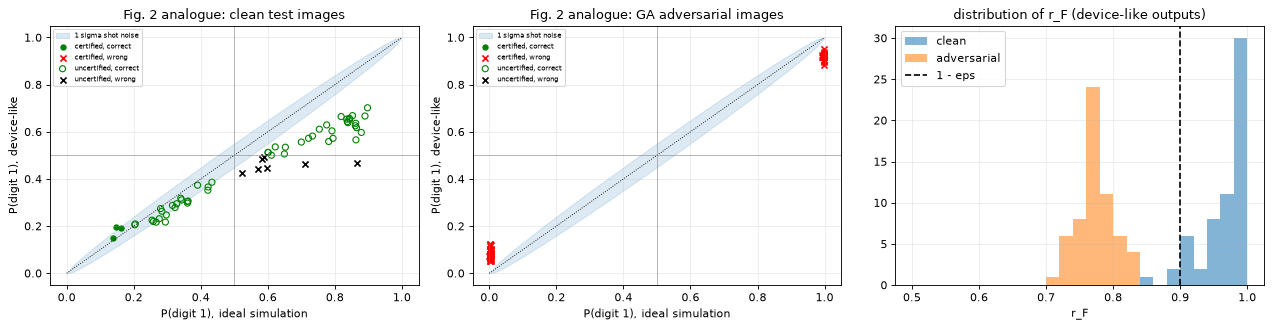

In [35]:
tname = "binary (0,1)"; r = RES[tname][0]; rec = ATT[(tname, "DRA-CQC", W1, "uniform")]; y_ = r["yt"][:rec["n"]]
rows = []
for lab, P in [("clean, ideal", rec["Pc"]), ("clean, device-like", rec["Pc_hw"]), ("adversarial, ideal", rec["Pa"]), ("adversarial, device-like", rec["Pa_hw"])]:
    cert_acc, cert, correct, rF = certified_accuracy(P, y_, EPS_CERT)
    unc = ~cert
    rows.append(dict(set=lab, accuracy=100 * correct.mean(), certified_accuracy=100 * cert_acc, uncertified_pct=100 * unc.mean(),
                     wrong_among_uncertified_pct=100 * (~correct[unc]).mean() if unc.any() else np.nan,
                     wrong_among_certified_pct=100 * (~correct[cert]).mean() if cert.any() else np.nan, median_rF=np.median(rF)))
CERT = pd.DataFrame(rows); display(CERT.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (P_id, P_hw, ttl) in zip(ax[:2], [(rec["Pc"], rec["Pc_hw"], "clean test images"), (rec["Pa"], rec["Pa_hw"], "GA adversarial images")]):
    _, cert, correct, rF = certified_accuracy(P_hw, y_, EPS_CERT)
    sd = np.sqrt(np.clip(P_id[:, 1] * (1 - P_id[:, 1]), 0, None) / SHOTS)
    xs = np.linspace(0, 1, 50); a.fill_between(xs, xs - 1 * np.sqrt(xs * (1 - xs) / SHOTS), xs + 1 * np.sqrt(xs * (1 - xs) / SHOTS), color="C0", alpha=.15, label="1 sigma shot noise")
    a.scatter(P_id[cert & correct, 1], P_hw[cert & correct, 1], c="g", s=22, label="certified, correct"); a.scatter(P_id[cert & ~correct, 1], P_hw[cert & ~correct, 1], c="r", marker="x", s=30, label="certified, wrong")
    a.scatter(P_id[~cert & correct, 1], P_hw[~cert & correct, 1], facecolors="none", edgecolors="g", s=30, label="uncertified, correct"); a.scatter(P_id[~cert & ~correct, 1], P_hw[~cert & ~correct, 1], c="k", marker="x", s=30, label="uncertified, wrong")
    a.plot([0, 1], [0, 1], "k:", lw=.8); a.axhline(.5, c="gray", lw=.5); a.axvline(.5, c="gray", lw=.5)
    a.set_xlabel("P(digit 1), ideal simulation"); a.set_ylabel("P(digit 1), device-like"); a.set_title(f"Fig. 2 analogue: {ttl}"); a.legend(fontsize=6)
for P, lab in [(rec["Pc_hw"], "clean"), (rec["Pa_hw"], "adversarial")]:
    ax[2].hist(robustness_fidelity(P), bins=np.linspace(0.5, 1, 26), alpha=.55, label=lab)
ax[2].axvline(1 - EPS_CERT, c="k", ls="--", label="1 - eps"); ax[2].set_xlabel("r_F"); ax[2].set_title("distribution of r_F (device-like outputs)"); ax[2].legend()
plt.tight_layout(); plt.show()

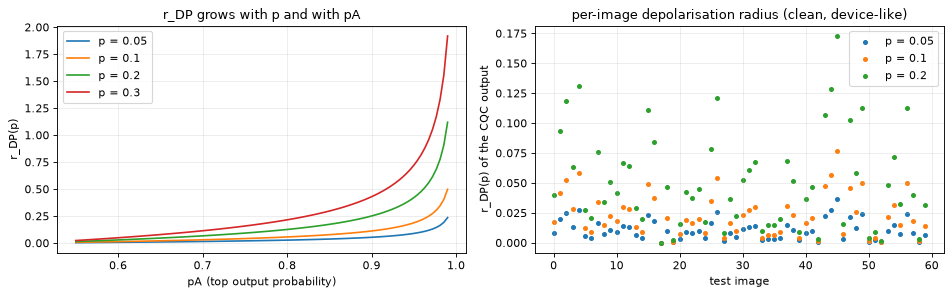

accuracy of the CQC outputs after extra depolarisation p = 0, 0.1, 0.2, 0.4: [100. 100. 100. 100.] (identical: depolarisation never flips the arg max)


In [36]:
# depolarisation: a depolarising channel rho -> (1-p) rho + p I/2 after the circuit shrinks populations towards 1/2 but never flips the
# argmax; what it buys is a certified radius r_DP(p) (eq. 4, transcribed). Trend only, cf. Fig. 3 of the paper.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pA = np.linspace(0.55, 0.99, 100)
for p in (0.05, 0.1, 0.2, 0.3): ax[0].plot(pA, r_dp(p, pA), label=f"p = {p}")
ax[0].set_xlabel("pA (top output probability)"); ax[0].set_ylabel("r_DP(p)"); ax[0].set_title("r_DP grows with p and with pA"); ax[0].legend()
P = rec["Pc_hw"]; pA_img = P.max(1)
for p in (0.05, 0.1, 0.2): ax[1].scatter(np.arange(len(pA_img)), r_dp(p, pA_img), s=12, label=f"p = {p}")
ax[1].set_xlabel("test image"); ax[1].set_ylabel("r_DP(p) of the CQC output"); ax[1].set_title("per-image depolarisation radius (clean, device-like)"); ax[1].legend()
plt.tight_layout(); plt.show()
d = 0.2; acc_dep = []
for p in (0, 0.1, 0.2, 0.4):                        # global depolarisation of the final scores: argmax unchanged
    s_ = rec["Pc"] * (1 - p) + p / 2; acc_dep.append(100 * (s_.argmax(1) == y_).mean())
print("accuracy of the CQC outputs after extra depolarisation p = 0, 0.1, 0.2, 0.4:", np.round(acc_dep, 1), "(identical: depolarisation never flips the arg max)")

## 9. Side-by-side comparison with the paper (Table 1 and text)

In [37]:
def verdict(paper, ours, tol=2.0):
    if paper is None or ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded by {d:+.1f} pts" if d > 0 else f"not reached ({d:+.1f} pts)"

def metric(tname, model, col):
    row = METRICS[(METRICS.task == tname) & (METRICS.model == model)]
    return float(row.iloc[0][col]) if len(row) else None
def adv(tname, model, noisy=False):
    rec = ATT.get((tname, model, W1, "uniform"));
    return None if rec is None else rec["adv_acc_hw" if noisy else "adv_acc"]

B, M3, M4 = "binary (0,1)", "3-class (0,1,2)", "4-class (0,1,2,3)"
claims = [  # (claim, paper value, notebook value)
 ("PCA-DRA binary: train acc, simulation", 100.0, metric(B, "PCA-DRA", "train_acc")),
 ("PCA-DRA binary: test acc, simulation", 99.61, metric(B, "PCA-DRA", "test_acc")),
 ("PCA-DRA binary: test acc, quantum computer (here: device-like sim)", 99.52, metric(B, "PCA-DRA", "test_acc_noisy")),
 ("PCA-DRA binary: adversarial acc, simulation", 45.14, adv(B, "PCA-DRA")),
 ("PCA-DRA binary: adversarial acc, quantum computer (device-like)", 45.24, adv(B, "PCA-DRA", True)),
 ("PCA-DRA 3-class: train acc, simulation", 95.53, metric(M3, "PCA-DRA", "train_acc")),
 ("PCA-DRA 3-class: test acc, simulation", 93.32, metric(M3, "PCA-DRA", "test_acc")),
 ("PCA-DRA 3-class: test acc, noisy device (device-like)", 64.05, metric(M3, "PCA-DRA", "test_acc_noisy")),
 ("PCA-DRA 3-class: adversarial acc, simulation", 48.00, adv(M3, "PCA-DRA")),
 ("PCA-DRA 3-class: adversarial acc, noisy (device-like)", 44.00, adv(M3, "PCA-DRA", True)),
 ("DRA-CQC binary: train acc, simulation", 99.16, metric(B, "DRA-CQC", "train_acc")),
 ("DRA-CQC binary: test acc, simulation", 98.28, metric(B, "DRA-CQC", "test_acc")),
 ("DRA-CQC binary: test acc, ion-trap device (device-like)", 92.00, metric(B, "DRA-CQC", "test_acc_noisy")),
 ("DRA-CQC binary: adversarial acc, simulation", 90.00, adv(B, "DRA-CQC")),
 ("DRA-CQC binary: adversarial acc, ion-trap device (device-like)", 88.00, adv(B, "DRA-CQC", True)),
 ("DRA-CQC 3-class: train acc, simulation", 94.97, metric(M3, "DRA-CQC", "train_acc")),
 ("DRA-CQC 3-class: test acc, simulation", 94.10, metric(M3, "DRA-CQC", "test_acc")),
 ("DRA-CQC 3-class: test acc, noisy device (device-like)", 93.49, metric(M3, "DRA-CQC", "test_acc_noisy")),
 ("DRA-CQC 3-class: adversarial acc, simulation", 82.00, adv(M3, "DRA-CQC")),
 ("DRA-CQC 3-class: adversarial acc, noisy (device-like)", 78.10, adv(M3, "DRA-CQC", True)),
 ("DRA-CQC 4-class: train acc, simulation", 92.49, metric(M4, "DRA-CQC", "train_acc")),
 ("DRA-CQC 4-class: test acc, simulation", 91.64, metric(M4, "DRA-CQC", "test_acc")),
 ("DRA-CQC 4-class: test acc, noisy device (device-like)", 85.81, metric(M4, "DRA-CQC", "test_acc_noisy")),
]
cq_b = ATT[(B, "DRA-CQC", W1, "uniform")]; dr_b = ATT[(B, "PCA-DRA", W1, "uniform")]
cert_row = CERT[CERT.set == "clean, device-like"].iloc[0]
claims += [
 ("mean pixel change of the GA images (w0=w1=1), %  [paper: 12.6 %, PCA-DRA]", 12.6, dr_b["mean_abs_dx"]),
 ("CQC more robust than PCA-DRA under the GA (binary): adv-acc gap CQC - PCA-DRA, pts [paper: +44.9]", 44.86, cq_b["adv_acc"] - dr_b["adv_acc"]),
 ("CQC binary: share of uncertified clean points at eps=0.1, %  [paper: 12 %]", 12.0, cert_row.uncertified_pct),
 ("CQC binary: wrong among uncertified clean points, %  [paper: 25 %]", 25.0, cert_row.wrong_among_uncertified_pct),
 ("CQC binary: wrong among certified clean points, %  [paper: 5.7 %]", 5.7, cert_row.wrong_among_certified_pct),
 ("hardware-noise drop PCA-DRA 3-class minus CQC 3-class (pts) [paper: 29.3 vs 0.6]", 29.27 - 0.61,
   (metric(M3, "PCA-DRA", "test_acc") - metric(M3, "PCA-DRA", "test_acc_noisy")) - (metric(M3, "DRA-CQC", "test_acc") - metric(M3, "DRA-CQC", "test_acc_noisy"))),
]
claims += [
 ("PCA-DRA binary: adversarial acc, equal-budget GA (RMSE <= 0.2) [extra check vs the paper's 45.14]", 45.14, ATTB[("PCA-DRA", 0.2)]["adv_acc"]),
 ("DRA-CQC binary: adversarial acc, equal-budget GA (RMSE <= 0.2) [extra check vs the paper's 90.00]", 90.00, ATTB[("DRA-CQC", 0.2)]["adv_acc"]),
 ("CQC more robust than PCA-DRA at equal budget (RMSE <= 0.2): gap CQC - PCA-DRA, pts [paper: +44.9]", 44.86, ATTB[("DRA-CQC", 0.2)]["adv_acc"] - ATTB[("PCA-DRA", 0.2)]["adv_acc"]),
]
COMP = pd.DataFrame([dict(claim=c, paper=p, notebook=(None if o is None else round(float(o), 2)), verdict=verdict(p, o)) for c, p, o in claims])
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(COMP)
print(COMP.verdict.str.replace(r" .*", "", regex=True).value_counts().to_string())

,claim,paper,notebook,verdict
0,"PCA-DRA binary: train acc, simulation",100.00,99.61,reproduced
1,"PCA-DRA binary: test acc, simulation",99.61,99.44,reproduced
2,"PCA-DRA binary: test acc, quantum computer (here: device-like sim)",99.52,99.44,reproduced
3,"PCA-DRA binary: adversarial acc, simulation",45.14,0.00,not reached (-45.1 pts)
4,"PCA-DRA binary: adversarial acc, quantum computer (device-like)",45.24,0.00,not reached (-45.2 pts)
5,"PCA-DRA 3-class: train acc, simulation",95.53,95.11,reproduced
6,"PCA-DRA 3-class: test acc, simulation",93.32,95.78,exceeded by +2.5 pts
7,"PCA-DRA 3-class: test acc, noisy device (device-like)",64.05,95.67,exceeded by +31.6 pts
8,"PCA-DRA 3-class: adversarial acc, simulation",48.00,16.67,not reached (-31.3 pts)
9,"PCA-DRA 3-class: adversarial acc, noisy (device-like)",44.00,20.83,not reached (-23.2 pts)


verdict
not           20
reproduced     6
exceeded       6


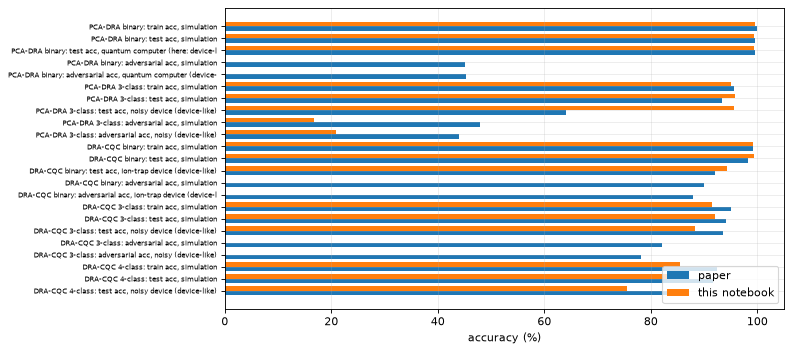

In [38]:
fig, ax = plt.subplots(figsize=(10, 4.5)); sub = COMP.iloc[:23].dropna()
ax.barh(np.arange(len(sub)) + 0.2, sub.paper, 0.4, label="paper"); ax.barh(np.arange(len(sub)) - 0.2, sub.notebook, 0.4, label="this notebook")
ax.set_yticks(range(len(sub))); ax.set_yticklabels([c[:58] for c in sub.claim], fontsize=6.5); ax.invert_yaxis(); ax.set_xlabel("accuracy (%)"); ax.legend(); plt.tight_layout(); plt.show()

## 10. Reading the paper critically

Numbers below are those of the full run stored in this notebook (`FAST_MODE = False`); with another seed or more images they will move by a few points (the equal-budget and sweep runs use only 10 images, so a binomial 95 % interval is about +-30 points there, +-13 points for the 60-image headline run).

* **What reproduced.** The clean accuracies of the PCA qubit (99.4 % binary, 95.8 % for 3 classes; paper 99.6 / 93.3 %) and of the binary DRA-CQC (99.4 %; paper 98.3 %) are in line with Table 1: a 9-parameter single qubit separates 0 from 1 and the 90-parameter DRA-CQC does it from raw pixels. For 3 and 4 classes our CQC is 2 and 7 points below the paper (92.0 / 84.2 % vs 94.1 / 91.6 %) with 108 and 126 parameters (the paper's 135 is not reproduced) and a short training budget.
* **Hardware numbers are not checkable.** Table 1's 'quantum computer' rows depend on an error budget that the paper does not publish. With our device-like model (per-gate depolarising 1 %, bit flip 0.5 %, phase flip 2 %, read-out flip 3 %, 100 shots) the PCA qubit loses almost nothing (3-class 95.7 % vs the paper's 64 %), and the CQC loses 5 / 4 / 9 points (binary / 3-class / 4-class; paper 6 / 1 / 6). The noise sweep shows the *opposite ordering* to the paper's message: the single qubit with a classical front end tolerates 8x our noise (3-class 87 %), the CQC (a mean of nine 100-shot read-outs of small score differences) collapses to chance at 2-4x. Which is right for the ion trap depends on its real error budget.
* **The headline robustness claim is not reproduced.** With the paper's GA budget (population 200, 500 generations) and literal operators, both quantum models are fooled on every attacked binary image (0 % adversarial accuracy; paper 45 % and 90 %), and in the 3-class task the PCA qubit keeps 17 % and the CQC 0 % (paper 48 % and 82 %). The images differ by about 29 % of the pixel range on average (paper: 12.6 %), and for the PCA qubit the GA simply *draws a '1' on top of the noise* (see the figure: the 'adversarial' image of a 0 is a bright vertical stroke), i.e. the attack changes the content, which no defence should be asked to resist. An attack that ends at a boundary-adjacent image would also produce Table 1's '45 %'.
* **At equal perturbation the ranking is opposite to the paper's.** With a hard budget `RMSE <= 0.2` (mean pixel change 11-13 %, matching the paper's 12.6 %) the GA drives the CQC to 0 % while the PCA qubit keeps about 60 % (paper: 45 % and 90 %); the classical baselines fed the same inputs keep 30-60 %. Random pixel noise alone (no adaptive attack) already drops the CQC to about 70 % accuracy at 10 % replaced pixels, where the PCA qubit and the classical models stay above 99 %; a separate helper run (see the note above) suggests this is not an artefact of our initialisation. Possible reasons for the disagreement: unspecified GA details, the definition of the output 'probability' (we use normalised populations; a softmax gave the same qualitative result in our development runs), training with or without noise, and the attack sample (10 images per budget here).
* **Unspecified experimental facts.** Training-set size, number of epochs and optimiser, the error budget of the device, the number of shots, whether the adversarial images were generated against the noiseless model or the device, and the 135-parameter 4-class model are not given; code and data are 'available upon request' only. The ion-trap results cannot be checked from this notebook at all.
* **Internal inconsistencies.** The text says `L = 7` layers, Table 1 says 9 parameters; the data are 'concatenated with a 1', consistent with 3 parameters per layer, i.e. 3 layers. The GA section initialises the population with uniform random pixels yet reports adversarial images that 'retain the original structure'.
* **FGSM is not infeasible.** The paper says gradient attacks are infeasible because the pipeline is non-differentiable. For the simulated model the gradient with respect to the pixels is exact (our back-propagation), and on hardware it can be estimated with the parameter-shift rule. A white-box attack would be a much harder test of the 'defence' than a random-search GA.
* **Certified robustness** (eq. 2) refers to a theoretical depolarising model and its threshold depends on how the output probability is defined. In our run only 30 % of clean ideal CQC outputs are certified at `eps = 0.1` (their probabilities are close to 0.5-0.8), against 88 % in the paper. Depolarising noise improves the *certificate* (`r_DP` grows with `p`), not the accuracy under attack: the arg max never changes.

## 11. Exercises

1. Run with `FAST_MODE = False` and `W1_SWEEP = (0.9, 1.2, 1.5)`: how does the adversarial accuracy of each quantum model depend on `w1`? Is there a `w1` for which the CQC reaches the paper's 90 %?
2. Replace the output probability of the CQC by `softmax(10 * score)` instead of the normalised score. Does the attack become easier or harder? Why?
3. Implement a white-box gradient attack (FGSM or PGD) on the simulated CQC using `loss_grad`'s back-propagation (add `d loss / d pixels`). Compare with the GA at an equal pixel budget.
4. Add `L=7` layers to the PCA-DRA and check whether more re-uploads increase the clean accuracy of the 3-class task.
5. Change `NOISE_HW`: which single noise channel (bit flip, phase flip, depolarising, read-out) hurts the 3-class PCA-DRA most? Fit the noise multiplier that reproduces the paper's 64 % and see whether the CQC then keeps 93 %.

## 12. Real hardware (optional)

The paper's processor is a barium trapped-ion qubit in Singapore; it is not available through any public service, so the 'quantum computer' rows above are *simulations*. The cell below only runs if `IBM_TOKEN` is set and sends the binary PCA-DRA circuits of 20 test images to an IBM device. It is **not** the paper's hardware, it has not been executed in this notebook's validation (no token on the build machine), and it is skipped otherwise.

In [39]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    svc = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = svc.least_busy(operational=True, simulator=False)
    r = RES["binary (0,1)"][0]; F_ = r["feats"](r["Xt"][:20]); th_ = r["dra"].theta
    circs = [gate_circuit(r["dra"].kinds, [float(np.r_[f_, 1.0] @ th_[l]) for l in range(3)]) for f_ in F_]
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    job = SamplerV2(mode=backend).run(pm.run(circs), shots=SHOTS)
    counts = [res.data.c.get_counts() for res in job.result()]
    pred = np.array([max(c, key=c.get) for c in counts]).astype(int)
    print(backend.name, "accuracy on 20 test images:", (pred == r["yt"][:20]).mean())
else:
    print("IBM_TOKEN is empty -> real-hardware cell skipped (the paper's trapped-ion device is not publicly accessible).")
print(f"Total run time of this notebook so far: {(time.time() - T0) / 60:.1f} min")

IBM_TOKEN is empty -> real-hardware cell skipped (the paper's trapped-ion device is not publicly accessible).
Total run time of this notebook so far: 119.8 min
